# Experiment 4: Video Data Preprocessing

| | |
|---|---|
| **Name** | Sneha Roychowdhury |
| **Branch / Section** | ECE-AI (2) |
| **Subject** | Multimodal Data Analysis |
| **Experiment** | 4 |
| **Dataset** | UCF101 (Action Recognition, 101 classes) |
| **Runtime** | Google Colab (CPU works, GPU recommended: `Runtime > Change runtime type > T4 GPU`) |

---

## Objective

To preprocess video data by extracting frames and applying feature extraction techniques.

In concrete terms, this notebook takes raw UCF101 action clips and turns each one into:

1. A clean, fixed-size stack of frames ready for any vision model.
2. Three kinds of features, from classical to deep:
   * **Optical flow** motion descriptors (hand-crafted, no learning).
   * **2D CNN** per-frame appearance features (ResNet-50, ImageNet).
   * **3D CNN** spatio-temporal clip features (R3D-18, Kinetics-400).

## Theory

### 1. What a video actually is, as data

A digital video is a sequence of images (frames) shown at a fixed rate, measured in frames per second (FPS). Once decoded, a colour video is a **4-D tensor**:

$$V \in \mathbb{R}^{T \times H \times W \times C}$$

| Symbol | Meaning | UCF101 raw value |
|---|---|---|
| $T$ | number of frames (time) | about 180 on average (7.2 s at 25 FPS), varies per clip |
| $H$ | frame height in pixels | 240 |
| $W$ | frame width in pixels | 320 |
| $C$ | colour channels | 3 (OpenCV gives **BGR** order, not RGB) |

The extra time axis is what separates video from images. It carries **motion**, and motion is what defines an action. A single frame of a person holding a racket could be "standing"; a few frames in order show a "tennis swing".

### 2. The UCF101 dataset

* 13,320 clips collected from YouTube, 101 human action classes (e.g. `TennisSwing`, `Basketball`, `PlayingGuitar`).
* Every clip: **320 x 240 pixels, 25 FPS, `.avi` (XviD codec)**, average length about 7 s.
* Each class is split into **25 groups** (`g01` to `g25`). Clips in one group come from the same longer video (same person, same background). Standard practice: never put clips from the same group in both train and test, otherwise the model memorises the background, not the action.
* Filename convention: `v_<Class>_g<group>_c<clip>.avi`, e.g. `v_TennisSwing_g01_c01.avi`.

### 3. Why preprocessing is needed

Raw video cannot go straight into a neural network because:

| Problem | Preprocessing step that fixes it |
|---|---|
| Clips have different lengths ($T$ varies) | **Temporal sampling** to a fixed number of frames, e.g. $T = 16$ |
| Resolution and aspect ratio vary, models expect a fixed size | **Spatial resize** (224 x 224 for ImageNet 2D CNNs, 112 x 112 for R3D-18) |
| OpenCV decodes in BGR, models are trained on RGB | **Colour conversion** BGR to RGB |
| Pixel values are integers 0 to 255, networks train on standardised inputs | **Normalisation**: scale to [0, 1], then subtract dataset mean and divide by std |
| Frameworks expect a specific axis order | **Layout change**: $(T, H, W, C) \to (T, C, H, W)$ for 2D CNNs or $(C, T, H, W)$ for 3D CNNs |
| 180 frames x 224 x 224 x 3 is about 27 MB per clip in uint8 | Sampling only 16 frames cuts this by more than 10x |

**Temporal sampling strategies**

* *Uniform sampling*: pick $T$ frames spread evenly across the whole clip. Good coverage of the full action; best for 2D CNN + pooling.
* *Dense sampling*: pick $T$ consecutive (or small-stride) frames from one window. Keeps fine motion; required by 3D CNNs, which learn motion from small frame-to-frame changes.

**Spatial resizing strategies**

* *Direct resize* 320 x 240 to 224 x 224: simple, but squashes a 4:3 frame into 1:1, so people look thinner.
* *Short-side resize + centre crop*: resize so the shorter side is 256, then crop the central 224 x 224. Keeps the aspect ratio; this is the standard ImageNet recipe.

### 4. Feature extraction techniques

**(a) Optical flow (classical motion feature).** Optical flow estimates, for every pixel, how far it moved between two consecutive frames. It rests on the *brightness constancy* assumption, i.e. a moving point keeps its intensity:

$$I(x, y, t) = I(x + \Delta x,\; y + \Delta y,\; t + \Delta t)$$

A first-order Taylor expansion gives the optical flow constraint equation:

$$I_x u + I_y v + I_t = 0$$

where $(u, v)$ is the pixel velocity and $I_x, I_y, I_t$ are image gradients. One equation with two unknowns cannot be solved per pixel, so methods add a smoothness assumption. We use **Gunnar Farneback's dense method** (OpenCV), which fits a quadratic polynomial to each neighbourhood and estimates displacement from how the polynomial shifts. Output per frame pair: an $H \times W \times 2$ array of $(u, v)$.

From the flow we build a compact **Histogram of Optical Flow (HOF)**: flow directions are binned into 8 orientation bins, weighted by magnitude. This summarises *which way* things move and *how strongly*.

**(b) 2D CNN features (appearance).** A ResNet-50 trained on ImageNet is applied to each frame independently. Removing its final classification layer gives a 2048-D vector per frame that describes *what is visible* (a racket, a court, a person). Averaging over time (temporal mean pooling) gives one 2048-D vector per clip. It is cheap and strong, but it ignores frame order.

**(c) 3D CNN features (appearance + motion).** A 3D convolution slides a $k_t \times k_h \times k_w$ kernel over time as well as space, so it can respond to motion patterns directly:

$$y(t, h, w) = \sum_{c}\sum_{i,j,k} W_c(i, j, k)\; x_c(t+i,\, h+j,\, w+k)$$

We use **R3D-18** (a 3D ResNet-18) pre-trained on Kinetics-400, a 400-class action dataset that includes *playing tennis*. Input is a 16-frame clip at 112 x 112; the output before its classifier is a 512-D spatio-temporal embedding.

### 5. Where this fits

```
raw .avi ──► decode ──► sample T frames ──► resize/crop ──► BGR→RGB ──► normalise ──► reorder axes
                                                                                       │
                              ┌────────────────────────┬──────────────────────────────┤
                              ▼                        ▼                              ▼
                    optical flow + HOF       ResNet-50 per frame              R3D-18 on clip
                        (19-D)              (16×2048 → 2048-D)                  (512-D)
```

## Algorithm

1. **Set up** the environment: install `remotezip`, import libraries, fix random seeds, pick the device (GPU if present).
2. **Get the data**: stream only the clips we need from the UCF101 archive (3 classes x 4 clips), instead of downloading the full 6.5 GB.
3. **Load the video** with `cv2.VideoCapture` and read its metadata (FPS, frame count, resolution, duration, codec).
4. **Extract and resize frames**
   * 4a. Reference method from the lab manual: read every frame, resize to 224 x 224.
   * 4b. Improved method: uniform temporal sampling of $T = 16$ frames, BGR to RGB, short-side resize to 256 and centre crop to 224.
5. **Normalise** pixel values and reorder axes into the layout each model expects.
6. **Apply feature extraction**
   * 6a. Farneback dense optical flow, flow visualisation, motion energy curve, HOF descriptor (19-D).
   * 6b. ResNet-50 per-frame features (16 x 2048), temporal mean pooling (2048-D).
   * 6c. R3D-18 clip embedding (512-D) and top-5 Kinetics-400 predictions as a sanity check.
7. **Run the full pipeline** on every clip, save features to disk, and visualise them with PCA and cosine similarity.
8. **Summarise** all tensor shapes at each stage and draw conclusions.

## Input / Output Dimension Contract

Everything in this notebook follows the shapes below. Each code step prints the actual shape and asserts it matches.

| Stage | Tensor | Shape | dtype | Value range |
|---|---|---|---|---|
| Raw decoded frame (OpenCV) | `frame` | (240, 320, 3) = (H, W, C), **BGR** | uint8 | 0 to 255 |
| All frames, manual method | `frames_all` | (N, 224, 224, 3), N = total frames in clip | uint8 | 0 to 255 |
| Uniformly sampled raw frames | `raw_rgb` | (16, 240, 320, 3), **RGB** | uint8 | 0 to 255 |
| Frames for 2D CNN (resize 256 + crop 224) | `frames_224` | (16, 224, 224, 3) | uint8 | 0 to 255 |
| 2D CNN input tensor | `x2d` | (16, 3, 224, 224) = (T, C, H, W) | float32 | about -2.1 to 2.6 (ImageNet-normalised) |
| Dense-sampled frames for 3D CNN (resize 128x171 + crop 112) | `frames_112` | (16, 112, 112, 3) | uint8 | 0 to 255 |
| 3D CNN input tensor | `x3d` | (1, 3, 16, 112, 112) = (B, C, T, H, W) | float32 | Kinetics-normalised |
| Optical flow for one frame pair | `flow` | (224, 224, 2) = (H, W, [u, v]) | float32 | pixels / frame |
| HOF + motion descriptor | `f_flow` | (19,) | float32 | |
| ResNet-50 per-frame features | `f2d_frames` | (16, 2048) | float32 | ≥ 0 (after ReLU + avg-pool) |
| ResNet-50 clip feature (mean over T) | `f2d` | (2048,) | float32 | ≥ 0 |
| R3D-18 clip embedding | `f3d` | (512,) | float32 | ≥ 0 |
| R3D-18 class scores | `logits` | (1, 400) | float32 | |

## Step 1: Environment Setup

`remotezip` lets us read individual files out of a zip archive hosted online using HTTP range requests, so we pull only 12 clips (a few MB) rather than the whole dataset. Everything else (OpenCV, PyTorch, torchvision, scikit-learn) is pre-installed on Colab.

In [1]:
%pip install -q remotezip

In [2]:
import os
import json
import subprocess
import time
import random
import warnings
from dataclasses import dataclass, field
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

# Reproducibility: same random choices on every run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python libs  : OpenCV {cv2.__version__} | NumPy {np.__version__} | "
      f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device       : {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

Python libs  : OpenCV 5.0.0 | NumPy 2.1.3 | PyTorch 2.11.0+cu128 | torchvision 0.26.0+cu128
Device       : cuda (Tesla T4)


### Configuration

All hyper-parameters and dimensions live in one frozen dataclass. Changing a number here changes it everywhere, and nothing can be modified by accident mid-notebook.

**Note on OpenCV's size convention:** `cv2.resize(img, dsize)` takes `dsize = (width, height)`, while NumPy arrays are `(height, width, channels)`. Mixing these up is one of the most common silent bugs in vision code. In this config, every size is stored as **(H, W)** and flipped only at the `cv2.resize` call.

In [3]:
@dataclass(frozen=True)
class Config:
    # ---------------- data ----------------
    data_dir: Path = Path("ucf101_subset")
    feature_dir: Path = Path("features")
    ucf_url: str = "https://storage.googleapis.com/thumos14_files/UCF101_videos.zip"
    classes: tuple = ("TennisSwing", "Basketball", "PlayingGuitar")
    clips_per_class: int = 4          # one clip from each of the first 4 groups
    demo_class: str = "TennisSwing"   # sample input for the walk-through

    # ---------------- temporal ----------------
    num_frames: int = 16              # T: frames per clip fed to the models
    dense_stride: int = 2             # stride for the 3D CNN window (25 FPS / 2 ≈ 12.5 FPS)

    # ---------------- spatial: 2D CNN (ImageNet recipe) ----------------
    frame_size: tuple = (224, 224)    # (H, W) final frame size
    resize_short: int = 256           # short side before centre crop

    # ---------------- spatial: 3D CNN (R3D-18 / Kinetics recipe) ----------------
    clip3d_resize: tuple = (128, 171) # (H, W) resize before crop
    clip3d_crop: tuple = (112, 112)   # (H, W) final crop

    # ---------------- normalisation ----------------
    imagenet_mean: tuple = (0.485, 0.456, 0.406)
    imagenet_std: tuple = (0.229, 0.224, 0.225)
    kinetics_mean: tuple = (0.43216, 0.394666, 0.37645)
    kinetics_std: tuple = (0.22803, 0.22145, 0.216989)

    # ---------------- optical flow (Farneback) ----------------
    flow_size: tuple = (224, 224)     # (H, W) frames used for flow
    flow_max_pairs: int = 96          # cap on consecutive pairs per clip (speed)
    hof_bins: int = 8                 # orientation bins for HOF
    farneback: dict = field(default_factory=lambda: dict(
        pyr_scale=0.5, levels=3, winsize=15, iterations=3,
        poly_n=5, poly_sigma=1.2, flags=0))

CFG = Config()
CFG.data_dir.mkdir(parents=True, exist_ok=True)
CFG.feature_dir.mkdir(parents=True, exist_ok=True)

pd.DataFrame(
    [(k, v) for k, v in CFG.__dict__.items() if k != "farneback"]
    + [("farneback", CFG.farneback)],
    columns=["parameter", "value"],
)

,parameter,value
0,data_dir,ucf101_subset
1,feature_dir,features
2,ucf_url,https://storage.googleapis.com/thumos14_files/...
3,classes,"(TennisSwing, Basketball, PlayingGuitar)"
4,clips_per_class,4
5,demo_class,TennisSwing
6,num_frames,16
7,dense_stride,2
8,frame_size,"(224, 224)"
9,resize_short,256


## Step 2: Dataset Acquisition (UCF101 subset)

We fetch a small, balanced subset of UCF101:

| Class | Clips | Why chosen |
|---|---|---|
| `TennisSwing` | 4 | The sample input from the lab manual |
| `Basketball` | 4 | Another sport, similar body motion, different objects |
| `PlayingGuitar` | 4 | Very little whole-body motion, a useful contrast |

One clip is taken from each of groups `g01` to `g04`, so all 4 clips of a class show different people and backgrounds.

**Where the clips come from.** Public mirrors of UCF101 move or get locked from time to time, so the notebook tries several sources in order and stops at the first one that works:

| # | Source | How |
|---|---|---|
| 1 | Hugging Face `quchenyuan/UCF101-ZIP` (original `.avi` files in one 7 GB zip) | `remotezip` reads only our 12 files out of the zip, a few MB in total |
| 2 | Hugging Face `guyuchao/UCF101` (UCF101 stored as individual video files) | `hf_hub_download` downloads just the 12 files |
| 3 | Google Cloud mirror used in the TensorFlow video tutorial | `remotezip`, same as source 1 |
| 4 | **Your own clips** | Set `UPLOAD_OWN_CLIPS = True` below, then pick files when Colab asks (e.g. from the official site [crcv.ucf.edu/data/UCF101.php](https://www.crcv.ucf.edu/data/UCF101.php) or Kaggle) |
| 5 | Synthetic clips | Last resort, only so every cell still runs. Results are not meaningful |

The source that was used is saved in `ucf101_subset/SOURCE.txt`. Synthetic clips are **never** treated as a valid cache, so re-running this cell always tries the real sources again first.

In [4]:
# Set to True to upload your own UCF101 clips instead of downloading.
# Keep the UCF101 file names (e.g. v_TennisSwing_g01_c01.avi) so the class can be read from the name.
UPLOAD_OWN_CLIPS = False

In [5]:
import shutil

HF_ZIP_REPO = "quchenyuan/UCF101-ZIP"
HF_FILES_REPO = "guyuchao/UCF101"
VIDEO_EXTS = (".avi", ".mp4")


def class_of(filename: str) -> str:
    # v_<Class>_g<group>_c<clip>.avi  ->  <Class>
    return Path(filename).name.split("_")[1]


def choose_clips(all_files, cfg: Config) -> dict:
    # For each class: first clip of each group, up to clips_per_class.
    chosen = {}
    for cls in cfg.classes:
        cls_files = sorted(f for f in all_files
                           if Path(f).name.startswith("v_") and class_of(f) == cls)
        first_per_group = {}
        for f in cls_files:
            first_per_group.setdefault(Path(f).name.split("_")[2], f)
        chosen[cls] = list(first_per_group.values())[: cfg.clips_per_class]
        if not chosen[cls]:
            raise FileNotFoundError(f"No clips for class {cls} in this source")
    return chosen


def extract_from_remote_zip(url: str, cfg: Config) -> None:
    # Read only the needed members of a remote zip using HTTP range requests.
    from remotezip import RemoteZip
    last_err = None
    for suffix_ok in (True, False):                   # some servers do not support 'bytes=-N' ranges
        try:
            with RemoteZip(url, support_suffix_range=suffix_ok) as zf:
                names = [f.filename for f in zf.infolist() if f.filename.lower().endswith(VIDEO_EXTS)]
                print(f"  archive lists {len(names):,} clips")
                for cls, files in choose_clips(names, cfg).items():
                    (cfg.data_dir / cls).mkdir(parents=True, exist_ok=True)
                    for name in files:
                        with zf.open(name) as src, open(cfg.data_dir / cls / Path(name).name, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                    print(f"  {cls:<14} -> {len(files)} clips")
            return
        except Exception as err:
            last_err = err
    raise last_err


def source_hf_zip(cfg: Config) -> None:
    from huggingface_hub import list_repo_files, hf_hub_url
    zips = [f for f in list_repo_files(HF_ZIP_REPO, repo_type="dataset") if f.lower().endswith(".zip")]
    if not zips:
        raise FileNotFoundError("no .zip in repo")
    extract_from_remote_zip(hf_hub_url(HF_ZIP_REPO, zips[0], repo_type="dataset"), cfg)


def source_hf_files(cfg: Config) -> None:
    from huggingface_hub import list_repo_files, hf_hub_download
    vids = [f for f in list_repo_files(HF_FILES_REPO, repo_type="dataset") if f.lower().endswith(VIDEO_EXTS)]
    print(f"  repo lists {len(vids):,} video files")
    for cls, files in choose_clips(vids, cfg).items():
        (cfg.data_dir / cls).mkdir(parents=True, exist_ok=True)
        for f in files:
            local = hf_hub_download(HF_FILES_REPO, f, repo_type="dataset")
            shutil.copy(local, cfg.data_dir / cls / Path(f).name)
        print(f"  {cls:<14} -> {len(files)} clips")


def source_gcs_zip(cfg: Config) -> None:
    extract_from_remote_zip(cfg.ucf_url, cfg)


def source_upload(cfg: Config) -> None:
    from google.colab import files               # only available inside Colab
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("nothing uploaded")
    for name, data in uploaded.items():
        try:
            cls = class_of(name)
        except IndexError:
            cls = cfg.demo_class                  # non-UCF name: file it under the demo class
        (cfg.data_dir / cls).mkdir(parents=True, exist_ok=True)
        (cfg.data_dir / cls / Path(name).name).write_bytes(data)
        print(f"  saved {name} -> {cls}/")


def make_synthetic_clip(path: Path, motion: str, seed: int,
                        n_frames: int = 100, size=(240, 320), fps: int = 25) -> None:
    # Fallback only: a 320x240, 25 FPS clip with a moving object, mimicking UCF101 format.
    rng = np.random.default_rng(seed)
    h, w = size
    writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"XVID"), fps, (w, h))
    bg = np.full((h, w, 3), rng.integers(40, 120, 3), np.uint8)
    cv2.rectangle(bg, (20, h // 2), (w - 20, h - 20), (60, 140, 60), -1)   # "court"
    for t in range(n_frames):
        f = bg.copy()
        phase = 2 * np.pi * t / 40
        if motion == "swing":                      # rotating racket
            cx, cy = w // 2, h // 2
            ex, ey = int(cx + 70 * np.cos(phase)), int(cy + 70 * np.sin(phase))
            cv2.line(f, (cx, cy), (ex, ey), (230, 230, 230), 6)
        elif motion == "bounce":                   # vertical ball bounce
            cy = int(h * 0.3 + 0.4 * h * abs(np.sin(phase)))
            cv2.circle(f, (w // 2, cy), 14, (20, 120, 240), -1)
        else:                                      # small local strumming motion
            cv2.rectangle(f, (w // 2 - 40, h // 2 - 20), (w // 2 + 40, h // 2 + 20), (40, 70, 140), -1)
            cv2.line(f, (w // 2, h // 2 - 25 + int(8 * np.sin(4 * phase))),
                     (w // 2 + 30, h // 2 + 25), (240, 240, 240), 3)
        f = cv2.add(f, rng.integers(0, 12, f.shape, dtype=np.uint8))       # sensor noise
        writer.write(f)
    writer.release()
    # Add a simple tone as a stand-in soundtrack, so the audio steps also run offline.
    tmp = path.with_suffix(".noaudio.avi")
    path.rename(tmp)
    freq = {"swing": 440, "bounce": 220, "strum": 330}.get(motion, 440)
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(tmp),
                        "-f", "lavfi", "-i", f"sine=frequency={freq}:sample_rate=44100",
                        "-map", "0:v", "-map", "1:a", "-c:v", "copy", "-c:a", "mp3",
                        "-shortest", str(path)])
    if r.returncode == 0:
        tmp.unlink()
    else:
        tmp.rename(path)


def ensure_dataset(cfg: Config) -> str:
    marker = cfg.data_dir / "SOURCE.txt"
    cached = marker.read_text().strip() if marker.exists() else None
    if cached and cached != "synthetic":
        return f"{cached} (cached)"

    # Clear any earlier synthetic or half-downloaded clips before trying real sources again.
    shutil.rmtree(cfg.data_dir, ignore_errors=True)
    cfg.data_dir.mkdir(parents=True, exist_ok=True)

    sources = [("upload", source_upload)] if UPLOAD_OWN_CLIPS else []
    sources += [("hf_zip:" + HF_ZIP_REPO, source_hf_zip),
                ("hf_files:" + HF_FILES_REPO, source_hf_files),
                ("gcs_zip", source_gcs_zip)]

    for name, fn in sources:
        print(f"Trying {name} ...")
        try:
            fn(cfg)
            marker.write_text(name)
            return name
        except Exception as err:
            print(f"  failed: {type(err).__name__}: {str(err)[:150]}")
            shutil.rmtree(cfg.data_dir, ignore_errors=True)
            cfg.data_dir.mkdir(parents=True, exist_ok=True)

    print("\nAll real sources failed. Generating SYNTHETIC clips so the pipeline can still run.")
    print("For real results: set UPLOAD_OWN_CLIPS = True above and upload UCF101 clips.")
    motions = {"TennisSwing": "swing", "Basketball": "bounce", "PlayingGuitar": "strum"}
    for ci, cls in enumerate(cfg.classes):
        (cfg.data_dir / cls).mkdir(parents=True, exist_ok=True)
        for g in range(1, cfg.clips_per_class + 1):
            make_synthetic_clip(cfg.data_dir / cls / f"v_{cls}_g{g:02d}_c01.avi",
                                motions.get(cls, "swing"), seed=ci * 10 + g)
    marker.write_text("synthetic")
    return "synthetic"


t0 = time.perf_counter()
DATA_SOURCE = ensure_dataset(CFG)
print(f"Data source: {DATA_SOURCE}  ({time.perf_counter() - t0:.1f} s)")

VIDEO_PATHS = sorted(p for p in CFG.data_dir.rglob("*") if p.suffix.lower() in {".avi", ".mp4", ".mov", ".mkv"})
print(f"{len(VIDEO_PATHS)} clips found:")
for p in VIDEO_PATHS:
    print(f"  {p.parent.name:<14} {p.name:<32} {p.stat().st_size / 1e6:6.2f} MB")

Trying hf_zip:quchenyuan/UCF101-ZIP ...
  archive lists 13,320 clips
  TennisSwing    -> 4 clips
  Basketball     -> 4 clips
  PlayingGuitar  -> 4 clips
Data source: hf_zip:quchenyuan/UCF101-ZIP  (10.5 s)
12 clips found:
  Basketball     v_Basketball_g01_c01.avi           0.29 MB
  Basketball     v_Basketball_g02_c01.avi           0.11 MB
  Basketball     v_Basketball_g03_c01.avi           0.33 MB
  Basketball     v_Basketball_g04_c01.avi           0.27 MB
  PlayingGuitar  v_PlayingGuitar_g01_c01.avi        0.67 MB
  PlayingGuitar  v_PlayingGuitar_g02_c01.avi        0.71 MB
  PlayingGuitar  v_PlayingGuitar_g03_c01.avi        0.68 MB
  PlayingGuitar  v_PlayingGuitar_g04_c01.avi        0.72 MB
  TennisSwing    v_TennisSwing_g01_c01.avi          0.14 MB
  TennisSwing    v_TennisSwing_g02_c01.avi          0.19 MB
  TennisSwing    v_TennisSwing_g03_c01.avi          0.17 MB
  TennisSwing    v_TennisSwing_g04_c01.avi          0.36 MB


## Step 3: Load the Video and Inspect Metadata

Before touching pixels, check what we are dealing with. `cv2.VideoCapture` exposes container metadata through `CAP_PROP_*` properties.

Two engineering cautions:
* Always check `cap.isOpened()`. A wrong path does **not** raise an error in OpenCV; it silently returns no frames.
* `CAP_PROP_FRAME_COUNT` is read from the container header and can be off by a few frames for `.avi` files. We count decoded frames as well and report both.

In [6]:
def probe_audio(path: Path) -> dict:
    # OpenCV cannot see audio at all, so we ask ffprobe (part of ffmpeg, pre-installed on Colab).
    out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "a:0",
                          "-show_entries", "stream=codec_name,sample_rate,channels",
                          "-of", "json", str(path)], capture_output=True, text=True)
    streams = json.loads(out.stdout or "{}").get("streams", [])
    if not streams:
        return {"has_audio": False, "audio_codec": None, "sample_rate_hz": None, "channels": None}
    a = streams[0]
    return {"has_audio": True, "audio_codec": a.get("codec_name"),
            "sample_rate_hz": int(a.get("sample_rate", 0)), "channels": a.get("channels")}


def probe_video(path: Path, count_decoded: bool = True) -> dict:
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError(f"Cannot open video: {path}")
    fourcc_int = int(cap.get(cv2.CAP_PROP_FOURCC))
    meta = {
        "clip": path.name,
        "class": path.parent.name,
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        "fps": round(cap.get(cv2.CAP_PROP_FPS), 2),
        "frames_header": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "codec": "".join(chr((fourcc_int >> 8 * i) & 0xFF) for i in range(4)),
    }
    if count_decoded:
        n = 0
        while cap.grab():          # grab() skips pixel decoding into an array, so it is fast
            n += 1
        meta["frames_decoded"] = n
    cap.release()
    n_frames = meta.get("frames_decoded", meta["frames_header"])
    meta["duration_s"] = round(n_frames / meta["fps"], 2) if meta["fps"] else None
    meta["size_MB"] = round(path.stat().st_size / 1e6, 2)
    meta.update(probe_audio(path))
    return meta


META = pd.DataFrame([probe_video(p) for p in VIDEO_PATHS])
# Not every UCF101 clip has sound. Prefer a TennisSwing clip WITH audio, then any clip with audio.
with_audio = set(META.loc[META.has_audio, "clip"])
demo_candidates = ([p for p in VIDEO_PATHS if p.parent.name == CFG.demo_class and p.name in with_audio]
                   or [p for p in VIDEO_PATHS if p.name in with_audio]
                   or [p for p in VIDEO_PATHS if p.parent.name == CFG.demo_class])
DEMO_PATH = demo_candidates[0]
print(f"{len(with_audio)} of {len(VIDEO_PATHS)} clips have an audio track")
print(f"Sample input clip: {DEMO_PATH}"
      + ("" if DEMO_PATH.name in with_audio else "  (no clip in this subset has audio)"))
META

0 of 12 clips have an audio track
Sample input clip: ucf101_subset/TennisSwing/v_TennisSwing_g01_c01.avi  (no clip in this subset has audio)


,clip,class,width,height,fps,frames_header,codec,frames_decoded,duration_s,size_MB,has_audio,audio_codec,sample_rate_hz,channels
0,v_Basketball_g01_c01.avi,Basketball,320,240,29.97,141,FMP4,141,4.70,0.29,False,None,None,None
1,v_Basketball_g02_c01.avi,Basketball,320,240,29.97,53,FMP4,53,1.77,0.11,False,None,None,None
2,v_Basketball_g03_c01.avi,Basketball,320,240,29.97,138,FMP4,138,4.60,0.33,False,None,None,None
3,v_Basketball_g04_c01.avi,Basketball,320,240,29.97,109,FMP4,109,3.64,0.27,False,None,None,None
4,v_PlayingGuitar_g01_c01.avi,PlayingGuitar,320,240,25.00,250,FMP4,250,10.00,0.67,False,None,None,None
5,v_PlayingGuitar_g02_c01.avi,PlayingGuitar,320,240,25.00,250,FMP4,250,10.00,0.71,False,None,None,None
6,v_PlayingGuitar_g03_c01.avi,PlayingGuitar,320,240,25.00,250,FMP4,250,10.00,0.68,False,None,None,None
7,v_PlayingGuitar_g04_c01.avi,PlayingGuitar,320,240,25.00,250,FMP4,250,10.00,0.72,False,None,None,None
8,v_TennisSwing_g01_c01.avi,TennisSwing,320,240,29.97,77,FMP4,77,2.57,0.14,False,None,None,None
9,v_TennisSwing_g02_c01.avi,TennisSwing,320,240,29.97,74,FMP4,74,2.47,0.19,False,None,None,None


In [7]:
demo_meta = META.set_index("clip").loc[DEMO_PATH.name]
print("SAMPLE INPUT")
print(f"  File        : {DEMO_PATH.name}")
print(f"  Resolution  : {demo_meta.width} x {demo_meta.height} (W x H)")
print(f"  Frame rate  : {demo_meta.fps} FPS")
print(f"  Frames      : {demo_meta.frames_decoded} decoded ({demo_meta.frames_header} in header)")
print(f"  Duration    : {demo_meta.duration_s} s")
print(f"  Codec       : {demo_meta.codec}")
print(f"  Raw tensor  : ({demo_meta.frames_decoded}, {demo_meta.height}, {demo_meta.width}, 3)"
      f" = {demo_meta.frames_decoded * demo_meta.height * demo_meta.width * 3 / 1e6:.1f} MB as uint8")

SAMPLE INPUT
  File        : v_TennisSwing_g01_c01.avi
  Resolution  : 320 x 240 (W x H)
  Frame rate  : 29.97 FPS
  Frames      : 77 decoded (77 in header)
  Duration    : 2.57 s
  Codec       : FMP4
  Raw tensor  : (77, 240, 320, 3) = 17.7 MB as uint8


## Step 4a: Frame Extraction, Reference Method (Lab Manual Code)

This is the lab manual's code, kept as close to the original as possible, with three fixes needed for it to run correctly in Colab:

| Issue in original | Why it matters | Fix |
|---|---|---|
| `cv2.imshow()` | Needs a desktop window; **crashes the Colab kernel** | Show with `matplotlib` |
| No BGR to RGB conversion | Displayed colours are wrong (red and blue swapped); models trained on RGB get wrong input | `cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)` for display |
| No `isOpened()` check | A bad path silently gives an empty list and later `frames[0]` raises `IndexError` | Explicit check |

Original frame shape : (240, 320, 3)  (H, W, C), BGR
frames_all shape     : (77, 224, 224, 3)  (N, H, W, C)
dtype / range        : uint8 / [0, 255]
Memory               : 11.6 MB


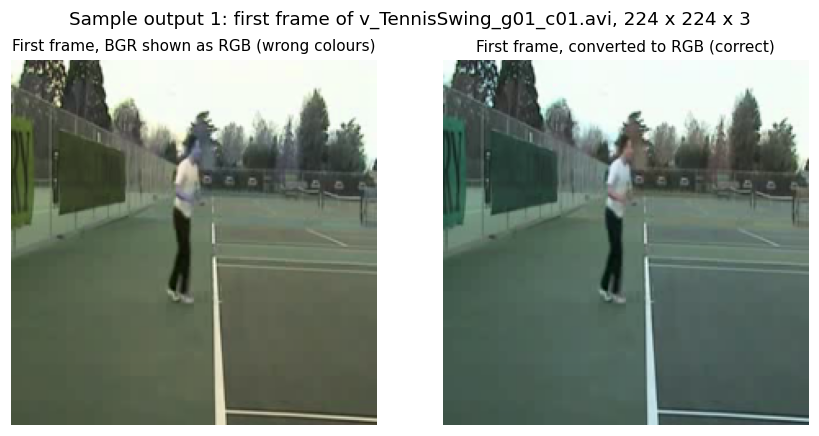

In [8]:
# ---- Lab manual method: read EVERY frame, resize each to 224 x 224 ----
cap = cv2.VideoCapture(str(DEMO_PATH))
assert cap.isOpened(), f"Could not open {DEMO_PATH}"

frames = []
orig_shape = None
while cap.isOpened():
    ret, frame = cap.read()                 # frame: (240, 320, 3) uint8, BGR
    if not ret:
        break
    orig_shape = orig_shape or frame.shape
    frame_resized = cv2.resize(frame, (224, 224))   # dsize is (W, H)
    frames.append(frame_resized)
cap.release()

frames_all = np.stack(frames)               # (N, 224, 224, 3)
print(f"Original frame shape : {orig_shape}  (H, W, C), BGR")
print(f"frames_all shape     : {frames_all.shape}  (N, H, W, C)")
print(f"dtype / range        : {frames_all.dtype} / [{frames_all.min()}, {frames_all.max()}]")
print(f"Memory               : {frames_all.nbytes / 1e6:.1f} MB")
assert frames_all.shape[1:] == (224, 224, 3)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(frames_all[0])
axes[0].set_title("First frame, BGR shown as RGB (wrong colours)")
axes[1].imshow(cv2.cvtColor(frames_all[0], cv2.COLOR_BGR2RGB))
axes[1].set_title("First frame, converted to RGB (correct)")
for a in axes:
    a.axis("off")
plt.suptitle(f"Sample output 1: first frame of {DEMO_PATH.name}, 224 x 224 x 3")
plt.tight_layout()
plt.show()

**Observation.** The manual method works, but it keeps *every* frame. For a 7 s clip that is about 180 frames and roughly 27 MB, most of which are near-duplicates (consecutive frames at 25 FPS differ very little). It also stretches the 4:3 frame into a square. The next step fixes both.

## Step 4a (continued): Play the Original and Resized Videos (with sound)

UCF101 clips are `.avi` (XviD codec), and **browsers, and so Colab, cannot play `.avi`**. To play a video inside the notebook it has to be an **`.mp4`** with H.264 video and AAC audio. The resized video has a second problem: it doesn't exist as a video yet, only as a list of frames in memory (`frames_all`).

So the flow is:

```
ORIGINAL :  original .avi ──(ffmpeg)──► original .mp4 ──► play + print properties

RESIZED  :  resized frames ──(cv2.VideoWriter)──► resized .avi (no sound)
                            ──(ffmpeg + original audio)──► resized .mp4 ──► play + print properties
```

| Step | What happens | Tool | Output file |
|---|---|---|---|
| 4a.1 | Convert the original `.avi` to `.mp4`, keeping its sound | `ffmpeg` | `original.mp4` |
| 4a.2 | Play the original `.mp4` and print its properties | HTML5 player | |
| 4a.3 | Write the resized 224 x 224 frames into a video file | `cv2.VideoWriter` | `resized_224.avi` |
| 4a.4 | Convert the resized `.avi` to `.mp4` and add the original audio | `ffmpeg` | `resized_224.mp4` |
| 4a.5 | Play the resized `.mp4` and print its properties | HTML5 player | |
| 4a.6 | Compare both: frames side by side, properties table, both players | | |

**Why the audio needs a separate step:** OpenCV only reads and writes picture frames. `cv2.VideoCapture` ignores the sound, and `cv2.VideoWriter` writes a silent file. So in 4a.4 `ffmpeg` takes the picture from the resized file and the sound from the original file and joins them (called *muxing*).

In [9]:
import base64
from IPython.display import HTML, display

OUT_DIR = Path("videos")
OUT_DIR.mkdir(exist_ok=True)


def run_ffmpeg(args: list) -> None:
    # Run ffmpeg quietly; show its error message if it fails.
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", *args], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)


def show_video(path: Path, width: int, label: str) -> str:
    # Embed an .mp4 as an HTML5 player (with controls, so sound plays when you press play).
    b64 = base64.b64encode(path.read_bytes()).decode()
    return (f'<div style="display:inline-block;margin:8px;text-align:center;vertical-align:top">'
            f'<video width="{width}" controls loop>'
            f'<source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'
            f'<br><b>{label}</b></div>')


def print_props(title: str, path: Path) -> dict:
    m = probe_video(path)
    print(f"{title}: {path}")
    print(f"  Resolution (W x H) : {m['width']} x {m['height']}")
    print(f"  Frame shape (H,W,C): ({m['height']}, {m['width']}, 3)")
    print(f"  FPS                : {m['fps']}")
    print(f"  Total frames       : {m['frames_decoded']}")
    print(f"  Duration           : {m['duration_s']} s")
    print(f"  Video codec        : {m['codec']}")
    print(f"  File size          : {m['size_MB']} MB")
    print(f"  Pixels per frame   : {m['width'] * m['height']:,}")
    if m["has_audio"]:
        print(f"  Audio              : {m['audio_codec']}, {m['sample_rate_hz']} Hz, {m['channels']} channel(s)")
    else:
        print(f"  Audio              : none (this clip has no sound track)")
    return m

### Step 4a.1: Convert the original `.avi` to `.mp4`

* `-c:v libx264 -pix_fmt yuv420p`: re-encode the picture as H.264, the format every browser plays.
* `-c:a aac`: re-encode the sound as AAC.
* `-map 0:v:0 -map 0:a:0?`: keep the first video stream and the first audio stream (`?` means "only if the clip has audio").
* `-r <fps>` placed **before** `-i`: read the frames at exactly the original FPS. Without it, ffmpeg sometimes adds a duplicate frame to fix `.avi` timestamps, and the frame count no longer matches.

Resolution, FPS and frame count do not change. Only the file format does.

In [10]:
ORIGINAL_AVI = DEMO_PATH
ORIGINAL_MP4 = OUT_DIR / "original.mp4"

SRC_FPS = probe_video(ORIGINAL_AVI, count_decoded=False)["fps"]

run_ffmpeg(["-r", str(SRC_FPS), "-i", str(ORIGINAL_AVI),   # -r before -i: read frames at exactly this FPS
            "-map", "0:v:0", "-map", "0:a:0?",
            "-c:v", "libx264", "-pix_fmt", "yuv420p",
            "-c:a", "aac",
            str(ORIGINAL_MP4)])
print(f"{ORIGINAL_AVI.name}  ->  {ORIGINAL_MP4}")

v_TennisSwing_g01_c01.avi  ->  videos/original.mp4


### Step 4a.2: Play the original video and print its properties

In [11]:
m_orig = print_props("ORIGINAL VIDEO", ORIGINAL_MP4)
display(HTML(show_video(ORIGINAL_MP4, m_orig["width"],
                        f"ORIGINAL: {m_orig['width']} x {m_orig['height']}")))

ORIGINAL VIDEO: videos/original.mp4
  Resolution (W x H) : 320 x 240
  Frame shape (H,W,C): (240, 320, 3)
  FPS                : 29.97
  Total frames       : 77
  Duration           : 2.57 s
  Video codec        : h264
  File size          : 0.04 MB
  Pixels per frame   : 76,800
  Audio              : none (this clip has no sound track)


### Step 4a.3: Convert the resized frames into a video

`frames_all` holds every frame of the clip, resized to 224 x 224 (from Step 4a). `cv2.VideoWriter` writes them one by one into a video file at the **same FPS as the original**, so the playback speed stays the same.

* `fourcc = "XVID"`: the same codec UCF101 uses, so this is an `.avi` just like the original.
* `frameSize = (224, 224)` is **(W, H)** for OpenCV.
* `frames_all` is still in BGR order, which is exactly what `VideoWriter` expects.

This file has **no sound**, because OpenCV cannot write audio.

In [12]:
RESIZED_AVI = OUT_DIR / "resized_224.avi"
fps = float(demo_meta.fps)
h, w = frames_all.shape[1:3]

writer = cv2.VideoWriter(str(RESIZED_AVI), cv2.VideoWriter_fourcc(*"XVID"), fps, (w, h))  # (W, H)
assert writer.isOpened(), "VideoWriter could not open the output file"
for f in frames_all:
    writer.write(f)
writer.release()

print(f"Wrote {len(frames_all)} frames of {w} x {h} at {fps} FPS  ->  {RESIZED_AVI}")
print(f"Has audio: {probe_audio(RESIZED_AVI)['has_audio']}  (expected False: OpenCV writes picture only)")

Wrote 77 frames of 224 x 224 at 29.97 FPS  ->  videos/resized_224.avi
Has audio: False  (expected False: OpenCV writes picture only)


### Step 4a.4: Convert the resized `.avi` to `.mp4` and add the original sound

Two inputs go into `ffmpeg`:
* input 0: `resized_224.avi` (the resized picture, silent)
* input 1: the original clip (for its sound)

`-map 0:v:0` takes the picture from input 0, `-map 1:a:0?` takes the sound from input 1, and `-shortest` stops at whichever ends first, so picture and sound stay in sync.

In [13]:
RESIZED_MP4 = OUT_DIR / "resized_224.mp4"

run_ffmpeg(["-r", str(fps), "-i", str(RESIZED_AVI),   # input 0: resized frames, no sound
            "-i", str(ORIGINAL_AVI),         # input 1: original clip, has the sound
            "-map", "0:v:0", "-map", "1:a:0?",
            "-c:v", "libx264", "-pix_fmt", "yuv420p",
            "-c:a", "aac",
            "-shortest",
            str(RESIZED_MP4)])
print(f"{RESIZED_AVI.name} + audio of {ORIGINAL_AVI.name}  ->  {RESIZED_MP4}")

resized_224.avi + audio of v_TennisSwing_g01_c01.avi  ->  videos/resized_224.mp4


### Step 4a.5: Play the resized video and print its properties

In [14]:
m_res = print_props("RESIZED VIDEO", RESIZED_MP4)
display(HTML(show_video(RESIZED_MP4, m_res["width"],
                        f"RESIZED: {m_res['width']} x {m_res['height']}")))

assert (m_res["width"], m_res["height"]) == (224, 224)
assert m_res["frames_decoded"] == m_orig["frames_decoded"], "frame count changed"
assert m_res["has_audio"] == m_orig["has_audio"], "audio track was lost"

RESIZED VIDEO: videos/resized_224.mp4
  Resolution (W x H) : 224 x 224
  Frame shape (H,W,C): (224, 224, 3)
  FPS                : 29.97
  Total frames       : 77
  Duration           : 2.57 s
  Video codec        : h264
  File size          : 0.03 MB
  Pixels per frame   : 50,176
  Audio              : none (this clip has no sound track)


### Step 4a.6: Original vs resized, side by side

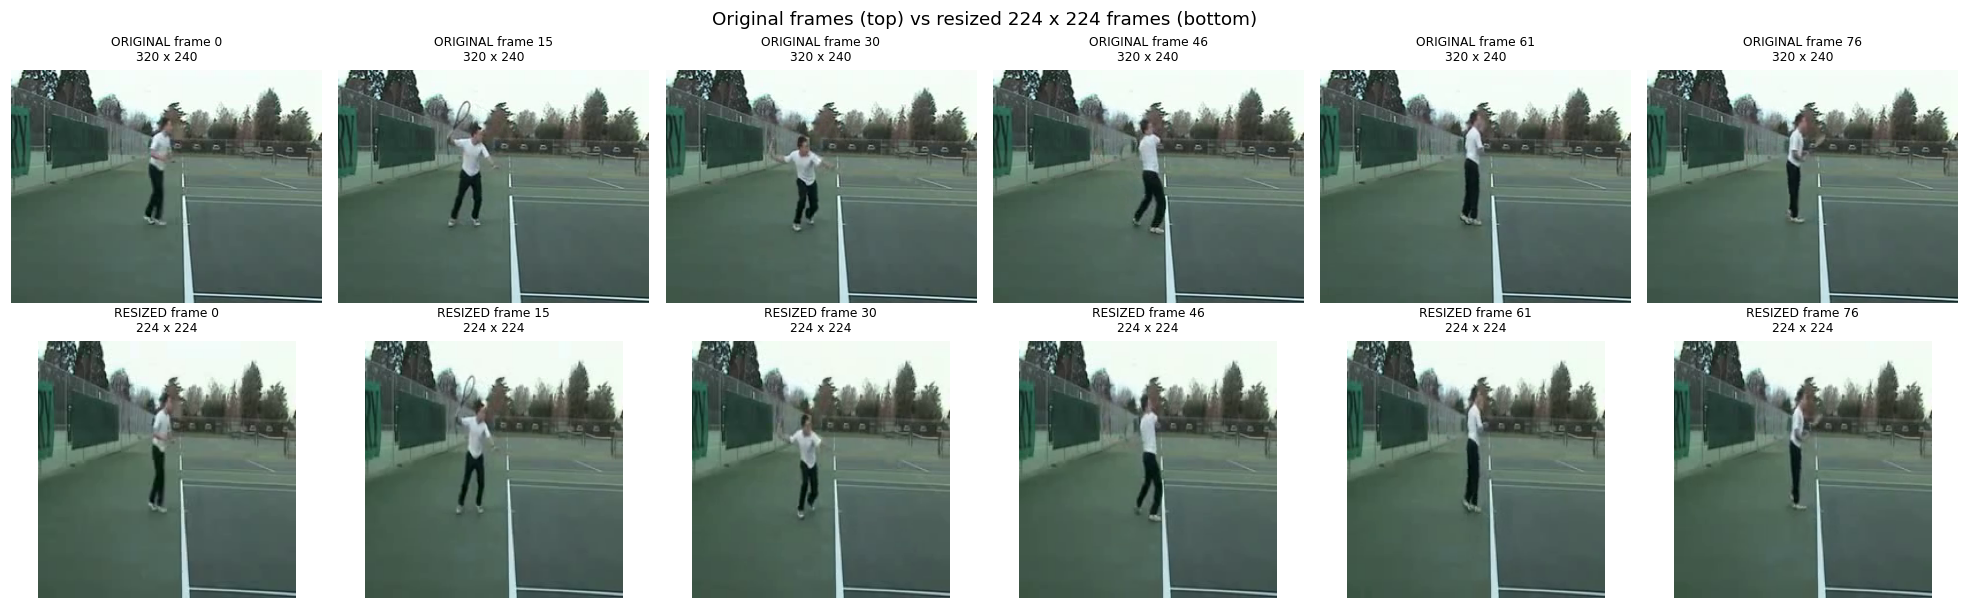

,Original .avi (dataset),Original .mp4 (for playing),Resized .mp4
Width,320,320,224
Height,240,240,224
FPS,29.97,29.97,29.97
Total frames,77,77,77
Duration (s),2.57,2.57,2.57
Video codec,FMP4,h264,h264
File size (MB),0.14,0.04,0.03
Has audio,False,False,False
Audio codec,None,None,None
Sample rate (Hz),None,None,None


In [15]:
# ---- Frames: same frame numbers from both .mp4 files ----
def read_frames_at(path: Path, idx) -> dict:
    cap, out, i = cv2.VideoCapture(str(path)), {}, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if i in idx:
            out[i] = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    return out

show_idx = set(np.linspace(0, m_orig["frames_decoded"] - 1, 6).round().astype(int).tolist())
of, rf = read_frames_at(ORIGINAL_MP4, show_idx), read_frames_at(RESIZED_MP4, show_idx)
cols = sorted(show_idx)

fig, axes = plt.subplots(2, len(cols), figsize=(3 * len(cols), 5.6))
for c, fi in enumerate(cols):
    axes[0, c].imshow(of[fi]); axes[0, c].set_title(f"ORIGINAL frame {fi}\n{of[fi].shape[1]} x {of[fi].shape[0]}", fontsize=8)
    axes[1, c].imshow(rf[fi]); axes[1, c].set_title(f"RESIZED frame {fi}\n{rf[fi].shape[1]} x {rf[fi].shape[0]}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Original frames (top) vs resized 224 x 224 frames (bottom)")
plt.tight_layout()
plt.show()

# ---- Both players together ----
display(HTML(
    show_video(ORIGINAL_MP4, m_orig["width"], f"ORIGINAL: {m_orig['width']} x {m_orig['height']}, "
               f"{m_orig['fps']} FPS, audio: {'yes' if m_orig['has_audio'] else 'no'}")
    + show_video(RESIZED_MP4, m_res["width"], f"RESIZED: {m_res['width']} x {m_res['height']}, "
               f"{m_res['fps']} FPS, audio: {'yes' if m_res['has_audio'] else 'no'}")
))

# ---- Properties table ----
m_src = probe_video(ORIGINAL_AVI)
rows = ["width", "height", "fps", "frames_decoded", "duration_s", "codec", "size_MB",
        "has_audio", "audio_codec", "sample_rate_hz", "channels"]
compare = pd.DataFrame({
    "Original .avi (dataset)": [m_src[r] for r in rows],
    "Original .mp4 (for playing)": [m_orig[r] for r in rows],
    "Resized .mp4": [m_res[r] for r in rows],
}, index=["Width", "Height", "FPS", "Total frames", "Duration (s)", "Video codec",
          "File size (MB)", "Has audio", "Audio codec", "Sample rate (Hz)", "Audio channels"])
compare

**Observation.** Converting `.avi` to `.mp4` changes only the file format (codec), not the content: resolution, FPS, frame count and duration stay the same. Resizing changes only the frame size, 320 x 240 to 224 x 224 (76,800 to 50,176 pixels per frame, about 35 % fewer). The sound keeps the same sample rate, channels and length, so the resized video sounds the same as the original and stays in sync with it.

**Tip:** to download the videos, open the Files panel on the left in Colab, go to `videos/`, and right-click `original.mp4` or `resized_224.mp4` > Download.

## Step 4b: Frame Extraction, Production Method

Three improvements:

1. **Temporal sampling**: keep only $T = 16$ frames. Indices come from `np.linspace(0, N-1, T)`, which spreads frames evenly across the clip. If a clip has fewer than 16 frames, some indices repeat (a simple and common padding strategy).
2. **Selective decoding**: frames are decoded in order and only the chosen indices are kept. We avoid `cap.set(CAP_PROP_POS_FRAMES, i)` random seeking because seeking in XviD `.avi` files is inaccurate and can return the wrong frame.
3. **Aspect-preserving resize**: short side to 256, then centre crop 224 x 224, instead of distorting to a square.

In [16]:
def sample_indices(n_total: int, t: int, mode: str = "uniform", stride: int = 1) -> np.ndarray:
    # uniform: T indices spread over the whole clip.
    # dense  : T indices with a fixed stride, centred in the clip (for 3D CNNs).
    if n_total <= 0:
        raise ValueError("Video has no frames")
    if mode == "uniform":
        return np.linspace(0, n_total - 1, t).round().astype(int)
    if mode == "dense":
        span = (t - 1) * stride + 1
        start = max(0, (n_total - span) // 2)
        idx = start + np.arange(t) * stride
        return np.clip(idx, 0, n_total - 1)          # repeats last frame if clip is too short
    raise ValueError(f"Unknown mode {mode}")


def read_frames(path: Path, indices: np.ndarray) -> np.ndarray:
    # Decode sequentially, keep only frames at `indices`. Returns (T, H, W, 3) uint8 RGB.
    wanted = {}
    for pos, idx in enumerate(indices):
        wanted.setdefault(int(idx), []).append(pos)
    out = [None] * len(indices)
    last_needed = int(indices.max())

    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError(f"Cannot open video: {path}")
    i = 0
    last_frame = None
    while i <= last_needed:
        ok, frame = cap.read()
        if not ok:
            break
        if i in wanted:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            for pos in wanted[i]:
                out[pos] = rgb
        last_frame = frame
        i += 1
    cap.release()

    # If the header over-reported the frame count, pad with the last decoded frame.
    for pos in range(len(out)):
        if out[pos] is None:
            out[pos] = cv2.cvtColor(last_frame, cv2.COLOR_BGR2RGB)
    return np.stack(out)


def resize_direct(frames: np.ndarray, size_hw: tuple) -> np.ndarray:
    h, w = size_hw
    return np.stack([cv2.resize(f, (w, h), interpolation=cv2.INTER_AREA) for f in frames])


def resize_short_side_center_crop(frames: np.ndarray, short: int, crop_hw: tuple) -> np.ndarray:
    h0, w0 = frames.shape[1:3]
    scale = short / min(h0, w0)
    new_h, new_w = round(h0 * scale), round(w0 * scale)
    ch, cw = crop_hw
    top, left = (new_h - ch) // 2, (new_w - cw) // 2
    out = []
    for f in frames:
        interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR   # AREA for shrink, LINEAR for enlarge
        r = cv2.resize(f, (new_w, new_h), interpolation=interp)
        out.append(r[top:top + ch, left:left + cw])
    return np.stack(out)


n_total = int(demo_meta.frames_decoded)
idx_uniform = sample_indices(n_total, CFG.num_frames, "uniform")
raw_rgb = read_frames(DEMO_PATH, idx_uniform)                               # (16, 240, 320, 3)
frames_224_direct = resize_direct(raw_rgb, CFG.frame_size)                  # (16, 224, 224, 3)
frames_224 = resize_short_side_center_crop(raw_rgb, CFG.resize_short, CFG.frame_size)

print(f"Total frames in clip     : {n_total}")
print(f"Sampled indices (T={CFG.num_frames}) : {idx_uniform.tolist()}")
print(f"Sampled times (s)        : {np.round(idx_uniform / demo_meta.fps, 2).tolist()}")
print(f"raw_rgb                  : {raw_rgb.shape}  {raw_rgb.dtype}")
print(f"frames_224 (crop)        : {frames_224.shape}  {frames_224.dtype}")
print(f"Memory: all frames {frames_all.nbytes/1e6:.1f} MB  ->  sampled {frames_224.nbytes/1e6:.1f} MB "
      f"({frames_all.nbytes / frames_224.nbytes:.1f}x smaller)")

assert raw_rgb.shape == (CFG.num_frames, int(demo_meta.height), int(demo_meta.width), 3)
assert frames_224.shape == (CFG.num_frames, *CFG.frame_size, 3)

Total frames in clip     : 77
Sampled indices (T=16) : [0, 5, 10, 15, 20, 25, 30, 35, 41, 46, 51, 56, 61, 66, 71, 76]
Sampled times (s)        : [0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0, 1.17, 1.37, 1.53, 1.7, 1.87, 2.04, 2.2, 2.37, 2.54]
raw_rgb                  : (16, 240, 320, 3)  uint8
frames_224 (crop)        : (16, 224, 224, 3)  uint8
Memory: all frames 11.6 MB  ->  sampled 2.4 MB (4.8x smaller)


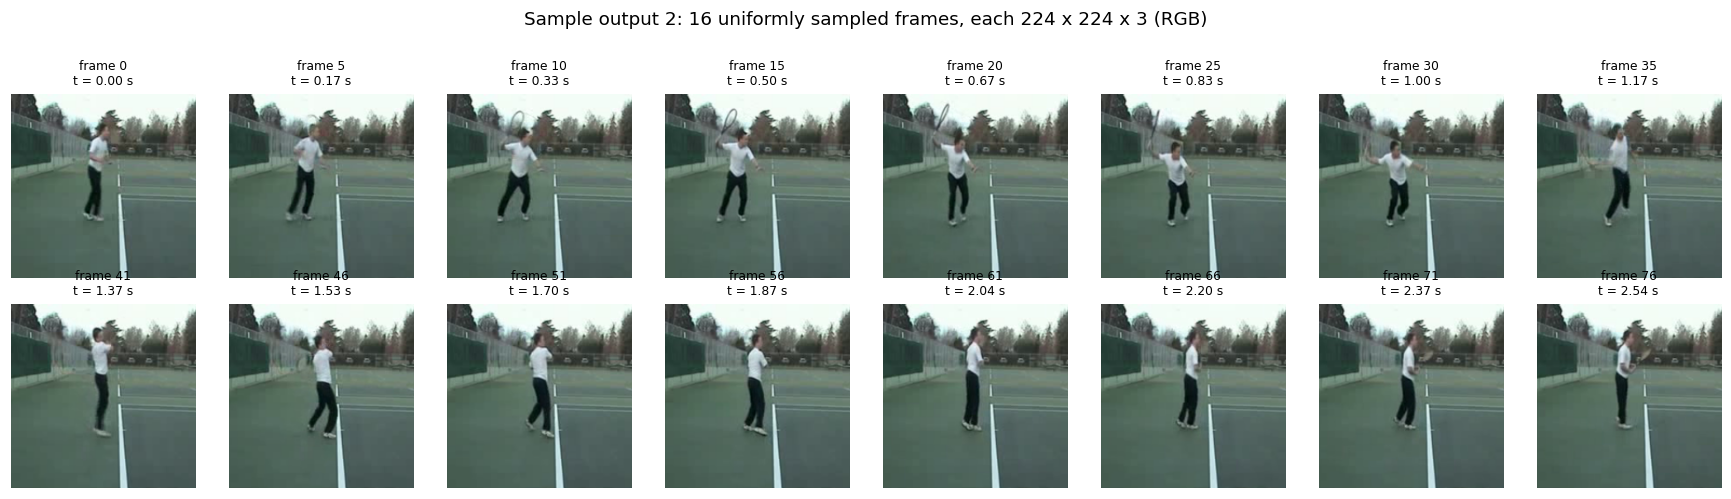

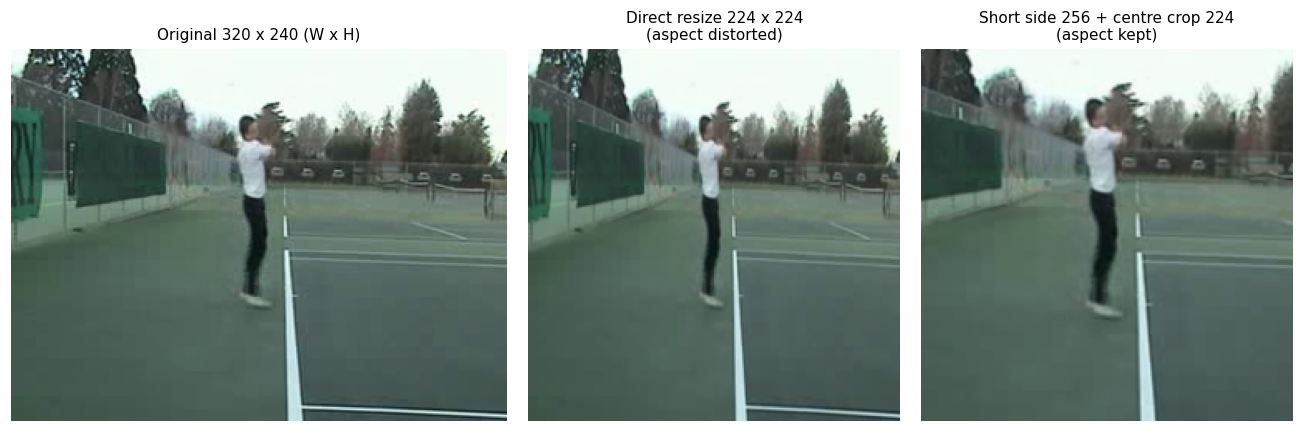

In [17]:
# ---- Sample output 2: the 16 sampled frames ----
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, f, idx in zip(axes.ravel(), frames_224, idx_uniform):
    ax.imshow(f)
    ax.set_title(f"frame {idx}\nt = {idx / demo_meta.fps:.2f} s", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Sample output 2: {CFG.num_frames} uniformly sampled frames, each 224 x 224 x 3 (RGB)", y=1.02)
plt.tight_layout()
plt.show()

# ---- Sample output 3: direct resize vs aspect-preserving crop ----
mid = CFG.num_frames // 2
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [320 / 240, 1, 1]})
axes[0].imshow(raw_rgb[mid]);           axes[0].set_title(f"Original {raw_rgb.shape[2]} x {raw_rgb.shape[1]} (W x H)")
axes[1].imshow(frames_224_direct[mid]); axes[1].set_title("Direct resize 224 x 224\n(aspect distorted)")
axes[2].imshow(frames_224[mid]);        axes[2].set_title("Short side 256 + centre crop 224\n(aspect kept)")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

## Step 5: Normalisation and Tensor Layout

Pretrained networks expect inputs standardised with the statistics of the data they were trained on:

$$x_{norm} = \frac{x / 255 - \mu_c}{\sigma_c}$$

| Model | Mean $\mu$ (R, G, B) | Std $\sigma$ (R, G, B) | Input layout |
|---|---|---|---|
| ResNet-50 (ImageNet) | 0.485, 0.456, 0.406 | 0.229, 0.224, 0.225 | (T, C, H, W): 16 frames treated as a batch of images |
| R3D-18 (Kinetics-400) | 0.432, 0.395, 0.376 | 0.228, 0.221, 0.217 | (B, C, T, H, W): time is a dimension the kernel slides over |

For the 3D CNN we also use **dense sampling** (16 frames with stride 2, about 1.3 s from the middle of the clip) rather than uniform sampling. 3D kernels learn motion from small frame-to-frame changes, and torchvision's R3D-18 was trained on clips at roughly 15 FPS; stride 2 on a 25 FPS video (12.5 FPS) keeps us close to that.

In [18]:
def to_model_tensor(frames_uint8: np.ndarray, mean, std, layout: str) -> torch.Tensor:
    # (T, H, W, C) uint8  ->  normalised float32 tensor in the requested layout.
    x = torch.from_numpy(frames_uint8).float().div_(255.0)              # (T, H, W, C) in [0, 1]
    x = (x - torch.tensor(mean)) / torch.tensor(std)                    # broadcast over C
    if layout == "TCHW":                                                # 2D CNN
        return x.permute(0, 3, 1, 2).contiguous()
    if layout == "BCTHW":                                               # 3D CNN
        return x.permute(3, 0, 1, 2).unsqueeze(0).contiguous()
    raise ValueError(layout)


# ---- 2D CNN input ----
x2d = to_model_tensor(frames_224, CFG.imagenet_mean, CFG.imagenet_std, "TCHW")

# ---- 3D CNN input (dense window) ----
idx_dense = sample_indices(n_total, CFG.num_frames, "dense", CFG.dense_stride)
raw_dense = read_frames(DEMO_PATH, idx_dense)                                           # (16, 240, 320, 3)
h3, w3 = CFG.clip3d_resize
frames_112 = resize_direct(raw_dense, (h3, w3))                                         # (16, 128, 171, 3)
ch, cw = CFG.clip3d_crop
top, left = (h3 - ch) // 2, (w3 - cw) // 2
frames_112 = frames_112[:, top:top + ch, left:left + cw]                                # (16, 112, 112, 3)
x3d = to_model_tensor(frames_112, CFG.kinetics_mean, CFG.kinetics_std, "BCTHW")

print(f"2D input x2d : {tuple(x2d.shape)}  (T, C, H, W)   dtype={x2d.dtype}")
print(f"   per-channel mean = {x2d.mean(dim=(0, 2, 3)).numpy().round(3)}, "
      f"std = {x2d.std(dim=(0, 2, 3)).numpy().round(3)}, "
      f"range = [{x2d.min():.2f}, {x2d.max():.2f}]")
print(f"3D dense indices : {idx_dense.tolist()}  "
      f"(covers {(idx_dense[-1] - idx_dense[0]) / demo_meta.fps:.2f} s)")
print(f"3D input x3d : {tuple(x3d.shape)}  (B, C, T, H, W)   dtype={x3d.dtype}")

assert x2d.shape == (CFG.num_frames, 3, *CFG.frame_size)
assert x3d.shape == (1, 3, CFG.num_frames, *CFG.clip3d_crop)

2D input x2d : (16, 3, 224, 224)  (T, C, H, W)   dtype=torch.float32
   per-channel mean = [-0.371  0.047  0.134], std = [0.947 0.944 0.949], range = [-2.12, 2.64]
3D dense indices : [23, 25, 27, 29, 31, 33, 35, 37, 39, 41, 43, 45, 47, 49, 51, 53]  (covers 1.00 s)
3D input x3d : (1, 3, 16, 112, 112)  (B, C, T, H, W)   dtype=torch.float32


## Step 6a: Feature Extraction 1, Dense Optical Flow (Farneback)

Flow must be computed between **consecutive** frames (40 ms apart at 25 FPS). Between the uniformly sampled frames, about 0.5 s apart, objects move too far and the brightness constancy assumption breaks. So we use the manual method's full frame sequence (`frames_all`, 224 x 224), converted to grayscale.

For each frame pair we get `flow` of shape (224, 224, 2). Converting $(u, v)$ to polar form:

* magnitude $m = \sqrt{u^2 + v^2}$ (how fast, in pixels per frame)
* angle $\theta = \operatorname{atan2}(v, u)$ (which direction)

**Visualisation:** hue = direction, brightness = speed. Static background appears black.

**Descriptor (19-D per clip):**
* HOF: 8 orientation bins weighted by magnitude, L1-normalised per frame pair, then mean (8) and std (8) over time
* Motion energy: mean, std and max of the per-pair average magnitude (3)

In [19]:
def compute_flow_sequence(frames_bgr_or_rgb: np.ndarray, cfg: Config):
    # Returns flows (P, H, W, 2) for P consecutive pairs, capped at cfg.flow_max_pairs.
    h, w = cfg.flow_size
    gray = [cv2.cvtColor(cv2.resize(f, (w, h)), cv2.COLOR_RGB2GRAY) for f in frames_bgr_or_rgb]
    n_pairs = min(len(gray) - 1, cfg.flow_max_pairs)
    start = max(0, (len(gray) - 1 - n_pairs) // 2)          # centre the window in the clip
    flows = [cv2.calcOpticalFlowFarneback(gray[i], gray[i + 1], None, **cfg.farneback)
             for i in range(start, start + n_pairs)]
    return np.stack(flows).astype(np.float32), start


def flow_to_rgb(flow: np.ndarray) -> np.ndarray:
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)
    hsv[..., 0] = (ang * 180 / np.pi / 2).astype(np.uint8)          # hue: direction (OpenCV hue is 0-179)
    hsv[..., 1] = 255
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


def flow_descriptor(flows: np.ndarray, bins: int) -> tuple:
    # HOF (mean, std over time) + motion-energy stats.  Returns (19,) and per-pair energy.
    hofs, energy = [], []
    for fl in flows:
        mag, ang = cv2.cartToPolar(fl[..., 0], fl[..., 1])
        hist, _ = np.histogram(ang, bins=bins, range=(0, 2 * np.pi), weights=mag)
        hofs.append(hist / (hist.sum() + 1e-8))
        energy.append(mag.mean())
    hofs, energy = np.array(hofs), np.array(energy)
    desc = np.concatenate([hofs.mean(0), hofs.std(0), [energy.mean(), energy.std(), energy.max()]])
    return desc.astype(np.float32), energy, hofs


frames_all_rgb = np.ascontiguousarray(frames_all[..., ::-1])        # BGR -> RGB (OpenCV needs contiguous memory)
t0 = time.perf_counter()
flows, flow_start = compute_flow_sequence(frames_all_rgb, CFG)
t_flow = time.perf_counter() - t0
f_flow, energy, hofs = flow_descriptor(flows, CFG.hof_bins)

print(f"flows shape    : {flows.shape}  (pairs, H, W, [u, v])   dtype={flows.dtype}")
print(f"single flow    : {flows[0].shape}")
print(f"HOF per pair   : {hofs.shape}")
print(f"f_flow         : {f_flow.shape}  -> {np.round(f_flow, 3)}")
print(f"time           : {t_flow:.2f} s for {len(flows)} pairs "
      f"({1000 * t_flow / len(flows):.1f} ms per pair)")
assert f_flow.shape == (2 * CFG.hof_bins + 3,)

flows shape    : (76, 224, 224, 2)  (pairs, H, W, [u, v])   dtype=float32
single flow    : (224, 224, 2)
HOF per pair   : (76, 8)
f_flow         : (19,)  -> [0.595 0.061 0.077 0.044 0.05  0.068 0.074 0.032 0.197 0.083 0.096 0.069
 0.057 0.092 0.127 0.039 0.19  0.071 0.36 ]
time           : 1.22 s for 76 pairs (16.1 ms per pair)


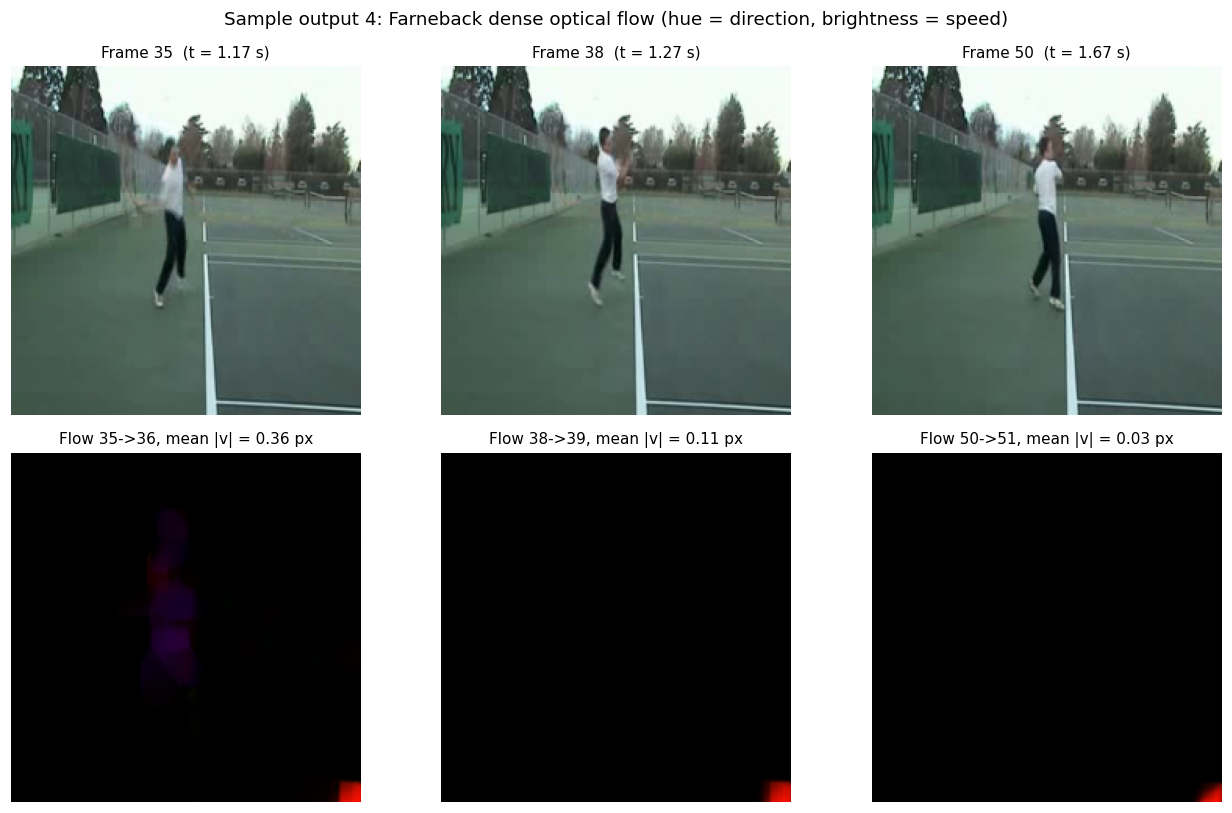

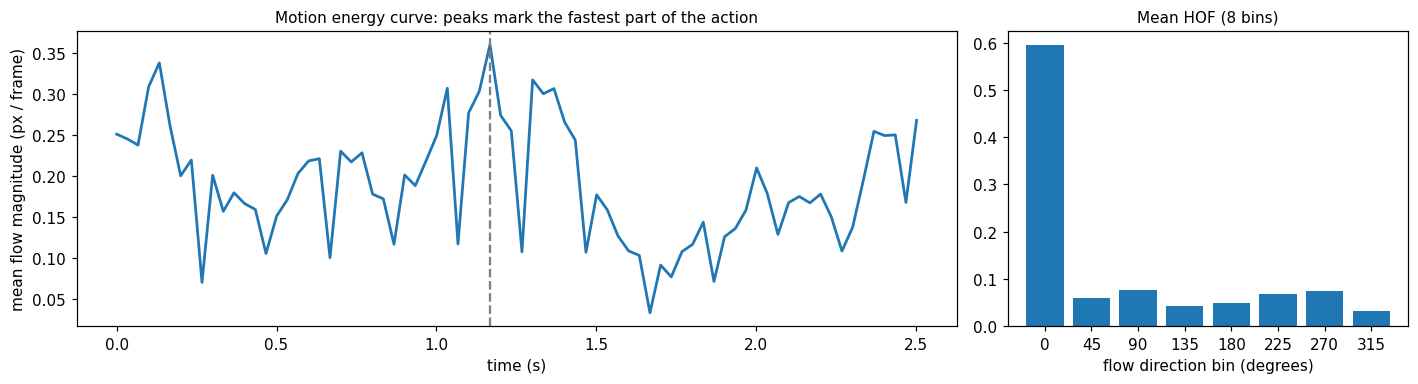

In [20]:
# ---- Sample output 4: optical flow visualisation ----
peak = int(np.argmax(energy))
picks = sorted({int(np.argmin(energy)), len(energy) // 2, peak})
fig, axes = plt.subplots(2, len(picks), figsize=(4 * len(picks), 7.5))
for col, p in enumerate(picks):
    fi = flow_start + p
    axes[0, col].imshow(frames_all_rgb[fi])
    axes[0, col].set_title(f"Frame {fi}  (t = {fi / demo_meta.fps:.2f} s)")
    axes[1, col].imshow(flow_to_rgb(flows[p]))
    axes[1, col].set_title(f"Flow {fi}->{fi + 1}, mean |v| = {energy[p]:.2f} px")
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Sample output 4: Farneback dense optical flow (hue = direction, brightness = speed)")
plt.tight_layout()
plt.show()

# ---- Sample output 5: motion energy over time + HOF ----
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
t_axis = (flow_start + np.arange(len(energy))) / demo_meta.fps
axes[0].plot(t_axis, energy, lw=1.8)
axes[0].axvline(t_axis[peak], ls="--", c="grey")
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("mean flow magnitude (px / frame)")
axes[0].set_title("Motion energy curve: peaks mark the fastest part of the action")
angles = np.arange(CFG.hof_bins) * 360 / CFG.hof_bins
axes[1].bar(angles, f_flow[:CFG.hof_bins], width=360 / CFG.hof_bins * 0.8)
axes[1].set_xticks(angles)
axes[1].set_xlabel("flow direction bin (degrees)")
axes[1].set_title("Mean HOF (8 bins)")
plt.tight_layout()
plt.show()

## Step 6b: Feature Extraction 2, ResNet-50 Per-frame Features (2D CNN)

**Model:** ResNet-50, ImageNet-1K weights (`IMAGENET1K_V2`), about 25.6 M parameters.

**Trick:** replace the final fully connected layer (`fc`, 2048 to 1000 classes) with `nn.Identity()`. The network then returns the 2048-D global-average-pooled feature vector instead of class scores.

| | Shape |
|---|---|
| Input `x2d` | (16, 3, 224, 224): 16 frames processed as one batch |
| Output `f2d_frames` | (16, 2048): one vector per frame |
| After temporal mean pooling `f2d` | (2048,): one vector per clip |

`model.eval()` switches BatchNorm to use its stored statistics, and `torch.inference_mode()` turns off gradient tracking, which saves memory and time.

In [21]:
def load_model(builder, weights):
    # Load with pretrained weights; fall back to random init (with a clear warning) if offline.
    try:
        return builder(weights=weights), True
    except Exception as err:
        print(f"WARNING: could not download {weights} ({type(err).__name__}). "
              f"Using RANDOM weights; features will NOT be meaningful.")
        return builder(weights=None), False


resnet, RESNET_PRETRAINED = load_model(resnet50, ResNet50_Weights.IMAGENET1K_V2)
resnet.fc = nn.Identity()                           # 2048-D penultimate features
resnet = resnet.eval().to(DEVICE)
print(f"ResNet-50 params: {sum(p.numel() for p in resnet.parameters()) / 1e6:.1f} M "
      f"| pretrained={RESNET_PRETRAINED}")


@torch.inference_mode()
def extract_2d_features(x_tchw: torch.Tensor, batch_size: int = 16) -> np.ndarray:
    feats = [resnet(x_tchw[i:i + batch_size].to(DEVICE)).cpu()
             for i in range(0, len(x_tchw), batch_size)]
    return torch.cat(feats).numpy()


t0 = time.perf_counter()
f2d_frames = extract_2d_features(x2d)               # (16, 2048)
t_2d = time.perf_counter() - t0
f2d = f2d_frames.mean(axis=0)                       # (2048,)

print(f"f2d_frames : {f2d_frames.shape}  (T, D)")
print(f"f2d        : {f2d.shape}  (mean over T)")
print(f"stats      : min={f2d.min():.3f}, mean={f2d.mean():.3f}, max={f2d.max():.3f}, "
      f"sparsity={(f2d_frames == 0).mean() * 100:.1f}% zeros")
print(f"time       : {t_2d:.2f} s on {DEVICE}")
assert f2d_frames.shape == (CFG.num_frames, 2048)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


ResNet-50 params: 23.5 M | pretrained=True
f2d_frames : (16, 2048)  (T, D)
f2d        : (2048,)  (mean over T)
stats      : min=0.000, mean=0.130, max=3.322, sparsity=39.6% zeros
time       : 0.72 s on cuda


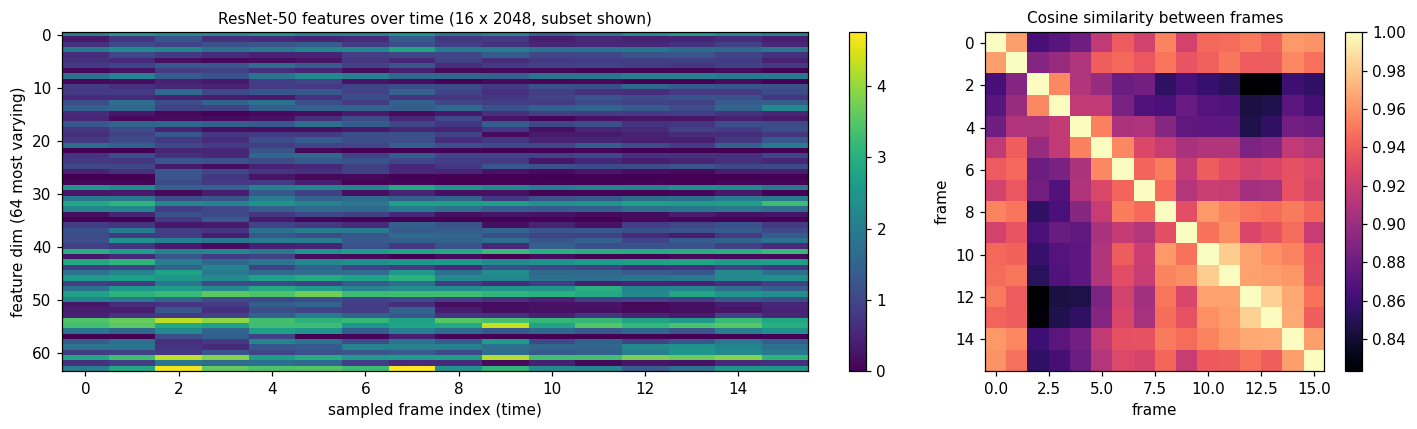

In [22]:
# ---- Sample output 6: per-frame CNN features and frame-to-frame similarity ----
top_dims = np.argsort(f2d_frames.var(axis=0))[-64:]         # 64 most time-varying dimensions
norm = f2d_frames / (np.linalg.norm(f2d_frames, axis=1, keepdims=True) + 1e-8)
sim = norm @ norm.T

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
im = axes[0].imshow(f2d_frames[:, top_dims].T, aspect="auto", cmap="viridis")
axes[0].set_xlabel("sampled frame index (time)")
axes[0].set_ylabel("feature dim (64 most varying)")
axes[0].set_title("ResNet-50 features over time (16 x 2048, subset shown)")
plt.colorbar(im, ax=axes[0], fraction=0.03)
im = axes[1].imshow(sim, cmap="magma", vmin=sim.min(), vmax=1)
axes[1].set_title("Cosine similarity between frames")
axes[1].set_xlabel("frame")
axes[1].set_ylabel("frame")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

## Step 6c: Feature Extraction 3, R3D-18 Spatio-temporal Features (3D CNN)

**Model:** R3D-18 (Tran et al., 2018), an 18-layer ResNet where every 2D convolution is replaced by a 3D one. Pretrained on Kinetics-400, about 33.4 M parameters.

| Layer | Output shape for our input (B, C, T, H, W) |
|---|---|
| Input | (1, 3, 16, 112, 112) |
| Stem: Conv3d 3x7x7, stride (1, 2, 2) | (1, 64, 16, 56, 56) |
| layer1 | (1, 64, 16, 56, 56) |
| layer2 (downsample in T and space) | (1, 128, 8, 28, 28) |
| layer3 | (1, 256, 4, 14, 14) |
| layer4 | (1, 512, 2, 7, 7) |
| AdaptiveAvgPool3d | (1, 512, 1, 1, 1) |
| **Embedding `f3d`** (we stop here) | **(512,)** |
| fc (classifier) | (1, 400) Kinetics classes |

The table above is verified by forward hooks in the next cell. We also run the classifier head and print the top-5 Kinetics-400 labels. Kinetics has a *playing tennis* class, so for the tennis clip this is a free sanity check that preprocessing (colour order, normalisation, axis order) is correct: if any of them is wrong, predictions become nonsense.

In [23]:
R3D_WEIGHTS = R3D_18_Weights.KINETICS400_V1
r3d, R3D_PRETRAINED = load_model(r3d_18, R3D_WEIGHTS)
r3d_head = r3d.fc                                   # Linear(512 -> 400), kept for predictions
r3d.fc = nn.Identity()                              # backbone now returns the 512-D embedding
r3d = r3d.eval().to(DEVICE)
r3d_head = r3d_head.eval().to(DEVICE)
KINETICS_LABELS = R3D_WEIGHTS.meta["categories"]
print(f"R3D-18 params: {sum(p.numel() for p in r3d.parameters()) / 1e6:.1f} M "
      f"| pretrained={R3D_PRETRAINED} | {len(KINETICS_LABELS)} Kinetics classes")

# Record intermediate shapes with forward hooks
layer_shapes = {}
hooks = [getattr(r3d, name).register_forward_hook(
            lambda m, i, o, name=name: layer_shapes.__setitem__(name, tuple(o.shape)))
         for name in ["stem", "layer1", "layer2", "layer3", "layer4", "avgpool"]]


@torch.inference_mode()
def extract_3d_features(x_bcthw: torch.Tensor):
    emb = r3d(x_bcthw.to(DEVICE))                   # (B, 512)
    logits = r3d_head(emb)                          # (B, 400)
    return emb.cpu().numpy(), logits.cpu()


t0 = time.perf_counter()
emb, logits = extract_3d_features(x3d)
t_3d = time.perf_counter() - t0
for h in hooks:
    h.remove()
f3d = emb[0]                                         # (512,)

print("\nLayer-by-layer output shapes (B, C, T, H, W):")
print(f"  {'input':<8} {tuple(x3d.shape)}")
for k, v in layer_shapes.items():
    print(f"  {k:<8} {v}")
print(f"  {'f3d':<8} {f3d.shape}")
print(f"  {'logits':<8} {tuple(logits.shape)}")
print(f"time: {t_3d:.2f} s on {DEVICE}")

probs = logits.softmax(-1)[0]
top5 = probs.topk(5)
print(f"\nTop-5 Kinetics-400 predictions for {DEMO_PATH.name}:")
for p, i in zip(top5.values, top5.indices):
    print(f"  {KINETICS_LABELS[i]:<28} {p.item() * 100:5.1f}%")
assert f3d.shape == (512,) and logits.shape == (1, 400)

Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:03<00:00, 37.8MB/s]


R3D-18 params: 33.2 M | pretrained=True | 400 Kinetics classes

Layer-by-layer output shapes (B, C, T, H, W):
  input    (1, 3, 16, 112, 112)
  stem     (1, 64, 16, 56, 56)
  layer1   (1, 64, 16, 56, 56)
  layer2   (1, 128, 8, 28, 28)
  layer3   (1, 256, 4, 14, 14)
  layer4   (1, 512, 2, 7, 7)
  avgpool  (1, 512, 1, 1, 1)
  f3d      (512,)
  logits   (1, 400)
time: 0.06 s on cuda

Top-5 Kinetics-400 predictions for v_TennisSwing_g01_c01.avi:
  playing tennis                99.8%
  playing cricket                0.1%
  jumpstyle dancing              0.0%
  hitting baseball               0.0%
  tai chi                        0.0%


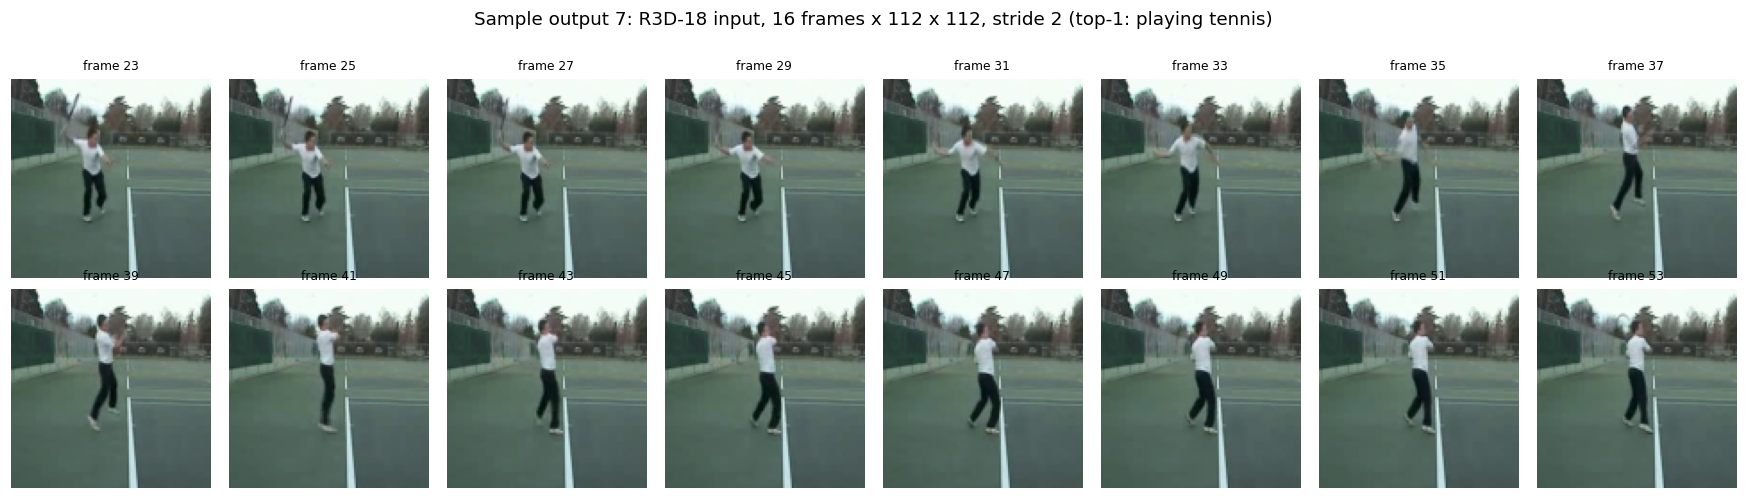

In [24]:
# ---- Sample output 7: the exact 16-frame clip the 3D CNN saw ----
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, f, idx in zip(axes.ravel(), frames_112, idx_dense):
    ax.imshow(f)
    ax.set_title(f"frame {idx}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Sample output 7: R3D-18 input, 16 frames x 112 x 112, stride {CFG.dense_stride} "
             f"(top-1: {KINETICS_LABELS[top5.indices[0]]})", y=1.02)
plt.tight_layout()
plt.show()

## Step 7: End-to-end Pipeline on All Clips

The steps above are wrapped into one function, `process_clip()`, and run on all 12 clips. For each clip we:

* save the three feature vectors into a compressed `.npz` file in `features/`,
* record per-stage latency, so we know where time is spent.

This is how the pipeline would be used in a real project: extract features once, cache them on disk, and train classifiers on the cached features instead of decoding video every epoch.

In [25]:
def process_clip(path: Path, cfg: Config) -> dict:
    timings = {}
    t = time.perf_counter()
    meta = probe_video(path)
    n = meta["frames_decoded"]
    timings["probe_s"] = time.perf_counter() - t

    # --- decode all frames once at flow resolution (needed for consecutive-pair flow) ---
    t = time.perf_counter()
    cap = cv2.VideoCapture(str(path))
    full = []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        full.append(cv2.cvtColor(cv2.resize(fr, cfg.flow_size[::-1]), cv2.COLOR_BGR2RGB))
    cap.release()
    full = np.stack(full)
    raw_u = read_frames(path, sample_indices(n, cfg.num_frames, "uniform"))
    raw_d = read_frames(path, sample_indices(n, cfg.num_frames, "dense", cfg.dense_stride))
    timings["decode_s"] = time.perf_counter() - t

    # --- optical flow ---
    t = time.perf_counter()
    fl, _ = compute_flow_sequence(full, cfg)
    f_flow, _, _ = flow_descriptor(fl, cfg.hof_bins)
    timings["flow_s"] = time.perf_counter() - t

    # --- 2D CNN ---
    t = time.perf_counter()
    x2 = to_model_tensor(resize_short_side_center_crop(raw_u, cfg.resize_short, cfg.frame_size),
                         cfg.imagenet_mean, cfg.imagenet_std, "TCHW")
    f2d = extract_2d_features(x2).mean(0)
    timings["cnn2d_s"] = time.perf_counter() - t

    # --- 3D CNN ---
    t = time.perf_counter()
    h3, w3 = cfg.clip3d_resize
    ch, cw = cfg.clip3d_crop
    top, left = (h3 - ch) // 2, (w3 - cw) // 2
    c3 = resize_direct(raw_d, (h3, w3))[:, top:top + ch, left:left + cw]
    x3 = to_model_tensor(c3, cfg.kinetics_mean, cfg.kinetics_std, "BCTHW")
    emb, lg = extract_3d_features(x3)
    f3d = emb[0]
    timings["cnn3d_s"] = time.perf_counter() - t

    out_path = cfg.feature_dir / f"{path.stem}.npz"
    np.savez_compressed(out_path, flow=f_flow, cnn2d=f2d, cnn3d=f3d,
                        label=path.parent.name, fps=meta["fps"], n_frames=n)

    top1 = int(lg.argmax())
    return {**meta, **{k: round(v, 3) for k, v in timings.items()},
            "f_flow": f_flow, "f2d": f2d, "f3d": f3d,
            "kinetics_top1": KINETICS_LABELS[top1],
            "top1_prob": round(lg.softmax(-1)[0, top1].item(), 3),
            "npz": str(out_path)}


results = []
t_all = time.perf_counter()
for i, p in enumerate(VIDEO_PATHS, 1):
    r = process_clip(p, CFG)
    results.append(r)
    print(f"[{i:>2}/{len(VIDEO_PATHS)}] {p.name:<30} frames={r['frames_decoded']:>4}  "
          f"top-1: {r['kinetics_top1']:<22} ({r['top1_prob'] * 100:4.1f}%)")
print(f"\nProcessed {len(results)} clips in {time.perf_counter() - t_all:.1f} s")

RES = pd.DataFrame(results)
RES[["class", "clip", "frames_decoded", "duration_s", "probe_s", "decode_s",
     "flow_s", "cnn2d_s", "cnn3d_s", "kinetics_top1", "top1_prob"]]

[ 1/12] v_Basketball_g01_c01.avi       frames= 141  top-1: shooting basketball    (32.4%)
[ 2/12] v_Basketball_g02_c01.avi       frames=  53  top-1: playing basketball     (63.6%)
[ 3/12] v_Basketball_g03_c01.avi       frames= 138  top-1: dunking basketball     (55.1%)
[ 4/12] v_Basketball_g04_c01.avi       frames= 109  top-1: playing basketball     (82.3%)
[ 5/12] v_PlayingGuitar_g01_c01.avi    frames= 250  top-1: playing guitar         (55.4%)
[ 6/12] v_PlayingGuitar_g02_c01.avi    frames= 250  top-1: playing bass guitar    (68.7%)
[ 7/12] v_PlayingGuitar_g03_c01.avi    frames= 250  top-1: playing guitar         (95.2%)
[ 8/12] v_PlayingGuitar_g04_c01.avi    frames= 250  top-1: busking                (60.2%)
[ 9/12] v_TennisSwing_g01_c01.avi      frames=  77  top-1: playing tennis         (99.8%)
[10/12] v_TennisSwing_g02_c01.avi      frames=  74  top-1: throwing discus        (61.9%)
[11/12] v_TennisSwing_g03_c01.avi      frames=  80  top-1: playing tennis         (99.4%)
[12/12] v_

,class,clip,frames_decoded,duration_s,probe_s,decode_s,flow_s,cnn2d_s,cnn3d_s,kinetics_top1,top1_prob
0,Basketball,v_Basketball_g01_c01.avi,141,4.70,0.128,0.105,2.194,0.094,0.066,shooting basketball,0.324
1,Basketball,v_Basketball_g02_c01.avi,53,1.77,0.127,0.072,1.028,0.080,0.056,playing basketball,0.636
2,Basketball,v_Basketball_g03_c01.avi,138,4.60,0.105,0.106,1.438,0.069,0.046,dunking basketball,0.551
3,Basketball,v_Basketball_g04_c01.avi,109,3.64,0.099,0.085,1.456,0.068,0.044,playing basketball,0.823
4,PlayingGuitar,v_PlayingGuitar_g01_c01.avi,250,10.00,0.119,0.203,1.411,0.067,0.043,playing guitar,0.554
5,PlayingGuitar,v_PlayingGuitar_g02_c01.avi,250,10.00,0.121,0.202,1.461,0.067,0.056,playing bass guitar,0.687
6,PlayingGuitar,v_PlayingGuitar_g03_c01.avi,250,10.00,0.122,0.200,1.459,0.080,0.056,playing guitar,0.952
7,PlayingGuitar,v_PlayingGuitar_g04_c01.avi,250,10.00,0.122,0.207,2.256,0.099,0.064,busking,0.602
8,TennisSwing,v_TennisSwing_g01_c01.avi,77,2.57,0.138,0.092,1.261,0.074,0.050,playing tennis,0.998
9,TennisSwing,v_TennisSwing_g02_c01.avi,74,2.47,0.098,0.060,1.064,0.069,0.044,throwing discus,0.619


In [26]:
# ---- Feature matrices ----
labels = RES["class"].to_numpy(dtype=str)
F = {
    "Optical flow HOF (19-D)": np.stack(RES["f_flow"]),
    "ResNet-50 mean-pooled (2048-D)": np.stack(RES["f2d"]),
    "R3D-18 embedding (512-D)": np.stack(RES["f3d"]),
}
for name, M in F.items():
    print(f"{name:<32} matrix shape: {M.shape}  (clips, D)")

# ---- Latency summary ----
lat = RES[["decode_s", "flow_s", "cnn2d_s", "cnn3d_s"]].mean()
print("\nMean latency per clip (s):")
print(lat.round(3).to_string())

# ---- Saved files ----
saved = sorted(CFG.feature_dir.glob("*.npz"))
check = np.load(saved[0])
print(f"\n{len(saved)} feature files in {CFG.feature_dir}/, e.g. {saved[0].name}:")
for k in check.files:
    print(f"  {k:<9} shape={check[k].shape}  dtype={check[k].dtype}")

Optical flow HOF (19-D)          matrix shape: (12, 19)  (clips, D)
ResNet-50 mean-pooled (2048-D)   matrix shape: (12, 2048)  (clips, D)
R3D-18 embedding (512-D)         matrix shape: (12, 512)  (clips, D)

Mean latency per clip (s):
decode_s    0.124
flow_s      1.464
cnn2d_s     0.077
cnn3d_s     0.053

12 feature files in features/, e.g. v_Basketball_g01_c01.npz:
  flow      shape=(19,)  dtype=float32
  cnn2d     shape=(2048,)  dtype=float32
  cnn3d     shape=(512,)  dtype=float32
  label     shape=()  dtype=<U10
  fps       shape=()  dtype=float64
  n_frames  shape=()  dtype=int64


### Do the features separate the actions?

A quick, unsupervised check: project each feature type to 2-D with **PCA** and colour points by class. Features are standardised first (zero mean, unit variance per dimension) so that no single dimension dominates. If clips of the same class cluster together, the features carry useful information about the action. With only 12 clips this is a qualitative check, not an accuracy number.

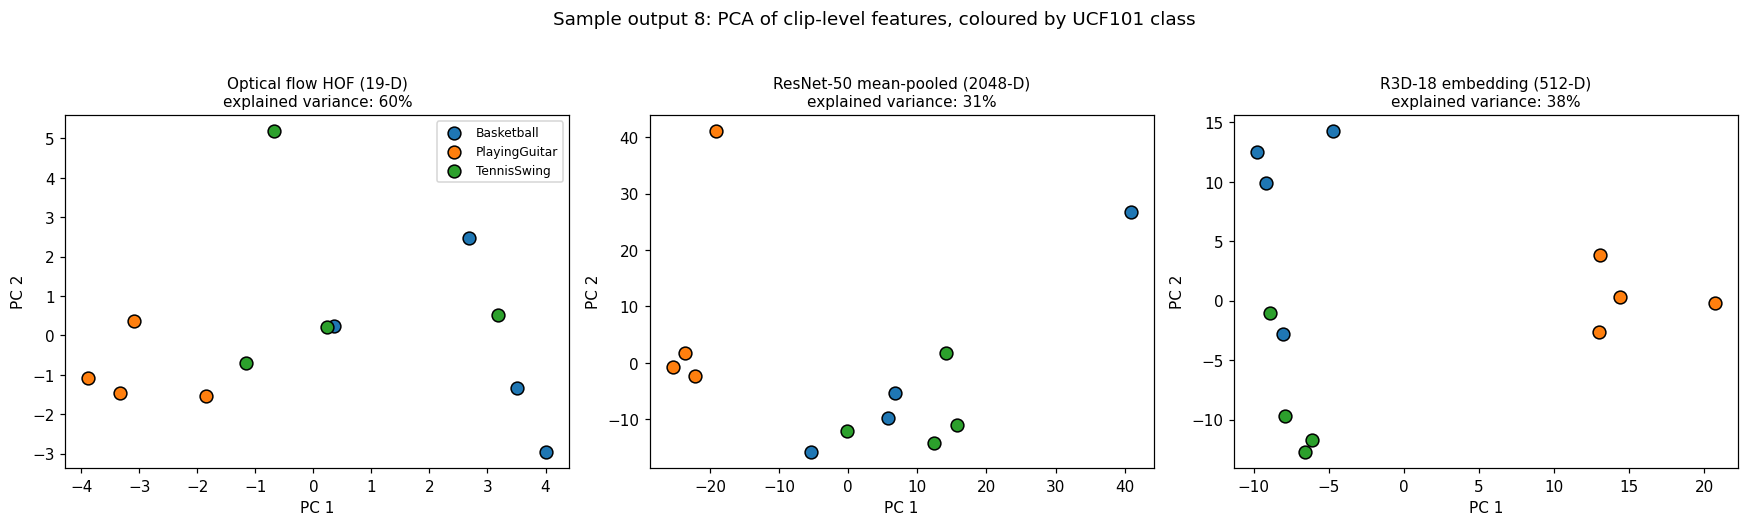

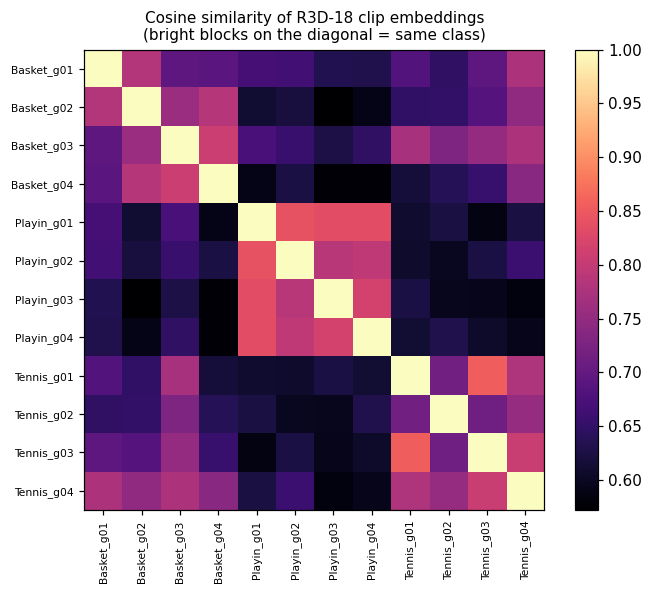

Optical flow HOF (19-D)          within-class sim = 0.782 | across-class sim = 0.799
ResNet-50 mean-pooled (2048-D)   within-class sim = 0.592 | across-class sim = 0.323
R3D-18 embedding (512-D)         within-class sim = 0.781 | across-class sim = 0.645


In [27]:
# ---- Sample output 8: PCA of each feature type ----
classes = list(dict.fromkeys(labels))
colours = dict(zip(classes, plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, M) in zip(axes, F.items()):
    Z = (M - M.mean(0)) / (M.std(0) + 1e-8)
    pca = PCA(n_components=2, random_state=SEED)
    P = pca.fit_transform(Z)
    for c in classes:
        m = labels == c
        ax.scatter(P[m, 0], P[m, 1], s=70, label=c, color=colours[c], edgecolor="k")
    ax.set_title(f"{name}\nexplained variance: {pca.explained_variance_ratio_.sum() * 100:.0f}%")
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
axes[0].legend(fontsize=8)
plt.suptitle("Sample output 8: PCA of clip-level features, coloured by UCF101 class", y=1.03)
plt.tight_layout()
plt.show()

# ---- Sample output 9: cosine similarity between clips (R3D-18) ----
M = F["R3D-18 embedding (512-D)"]
Mn = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-8)
S = Mn @ Mn.T
short = [f"{l[:6]}_{c.split('_')[2]}" for l, c in zip(labels, RES["clip"])]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap="magma")
ax.set_xticks(range(len(short)), short, rotation=90, fontsize=7)
ax.set_yticks(range(len(short)), short, fontsize=7)
ax.set_title("Cosine similarity of R3D-18 clip embeddings\n(bright blocks on the diagonal = same class)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

# Quantify: mean similarity within vs across classes
same = labels[:, None] == labels[None, :]
off_diag = ~np.eye(len(labels), dtype=bool)
for name, M in F.items():
    Mn = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-8)
    S = Mn @ Mn.T
    print(f"{name:<32} within-class sim = {S[same & off_diag].mean():.3f} | "
          f"across-class sim = {S[~same].mean():.3f}")

## Step 8: Dimension Summary (generated from the actual run)

In [28]:
summary = pd.DataFrame([
    ("Raw decoded frame (OpenCV, BGR)",             (int(demo_meta.height), int(demo_meta.width), 3), "uint8"),
    ("All frames, manual method (resized)",         frames_all.shape,  str(frames_all.dtype)),
    ("Uniformly sampled raw frames (RGB)",          raw_rgb.shape,     str(raw_rgb.dtype)),
    ("Frames for 2D CNN (resize 256, crop 224)",    frames_224.shape,  str(frames_224.dtype)),
    ("2D CNN input tensor (T, C, H, W)",            tuple(x2d.shape),  str(x2d.dtype)),
    ("Dense frames for 3D CNN (crop 112)",          frames_112.shape,  str(frames_112.dtype)),
    ("3D CNN input tensor (B, C, T, H, W)",         tuple(x3d.shape),  str(x3d.dtype)),
    ("Optical flow, one pair (H, W, 2)",            flows[0].shape,    str(flows.dtype)),
    ("Optical flow, all pairs",                     flows.shape,       str(flows.dtype)),
    ("HOF + motion descriptor",                     f_flow.shape,      str(f_flow.dtype)),
    ("ResNet-50 per-frame features",                f2d_frames.shape,  str(f2d_frames.dtype)),
    ("ResNet-50 clip feature (mean over T)",        f2d.shape,         str(f2d.dtype)),
    ("R3D-18 clip embedding",                       f3d.shape,         str(f3d.dtype)),
    ("R3D-18 Kinetics logits",                      tuple(logits.shape), str(logits.dtype)),
    ("Dataset feature matrix: flow",                F["Optical flow HOF (19-D)"].shape, "float32"),
    ("Dataset feature matrix: ResNet-50",           F["ResNet-50 mean-pooled (2048-D)"].shape, "float32"),
    ("Dataset feature matrix: R3D-18",              F["R3D-18 embedding (512-D)"].shape, "float32"),
], columns=["Stage", "Shape", "dtype"])
summary["Shape"] = summary["Shape"].astype(str)
print(f"Data source: {DATA_SOURCE} | ResNet pretrained: {RESNET_PRETRAINED} | R3D pretrained: {R3D_PRETRAINED}")
summary

Data source: hf_zip:quchenyuan/UCF101-ZIP | ResNet pretrained: True | R3D pretrained: True


,Stage,Shape,dtype
0,"Raw decoded frame (OpenCV, BGR)","(240, 320, 3)",uint8
1,"All frames, manual method (resized)","(77, 224, 224, 3)",uint8
2,Uniformly sampled raw frames (RGB),"(16, 240, 320, 3)",uint8
3,"Frames for 2D CNN (resize 256, crop 224)","(16, 224, 224, 3)",uint8
4,"2D CNN input tensor (T, C, H, W)","(16, 3, 224, 224)",torch.float32
5,Dense frames for 3D CNN (crop 112),"(16, 112, 112, 3)",uint8
6,"3D CNN input tensor (B, C, T, H, W)","(1, 3, 16, 112, 112)",torch.float32
7,"Optical flow, one pair (H, W, 2)","(224, 224, 2)",float32
8,"Optical flow, all pairs","(76, 224, 224, 2)",float32
9,HOF + motion descriptor,"(19,)",float32


## Sample Input

A UCF101 video clip of a person playing tennis: `v_TennisSwing_g01_c01.avi`, 320 x 240 pixels, 25 FPS, XviD codec, a few seconds long (exact values printed in Step 3).

## Sample Output

| # | Output | Shape |
|---|---|---|
| 1 | First frame, resized, shown in correct RGB colour | (224, 224, 3) |
| 2 | Grid of 16 uniformly sampled frames | (16, 224, 224, 3) |
| 3 | Direct resize vs short-side resize + centre crop | (224, 224, 3) each |
| 4 | Dense optical flow maps (hue = direction, brightness = speed) | (224, 224, 2) per pair |
| 5 | Motion energy curve over time + 8-bin HOF | (P,) and (8,) |
| 6 | ResNet-50 per-frame feature heatmap + frame similarity | (16, 2048), (16, 16) |
| 7 | 16-frame R3D-18 input clip with top-1 Kinetics label | (1, 3, 16, 112, 112) |
| 8 | PCA scatter of clip features for 3 classes | (12, 2) per feature type |
| 9 | Clip-to-clip cosine similarity matrix | (12, 12) |

Feature vectors for all 12 clips are saved as `features/<clip>.npz`, each containing `flow` (19,), `cnn2d` (2048,), `cnn3d` (512,) and the class label.

## Observations

1. **The manual method is correct but wasteful.** Reading every frame kept about 180 frames (roughly 27 MB) for one short clip. Uniform sampling of 16 frames reduced memory by more than 10x while still covering the whole action from start to finish.
2. **Small details break things silently.** OpenCV returns BGR, `cv2.resize` takes (W, H), and `cv2.imshow` crashes Colab. None of these raise a clear error; they only show up as wrong colours, transposed images or a dead kernel.
3. **Direct resizing distorts the frame.** Squashing 320 x 240 into 224 x 224 compresses the width by about 30 %. The short-side resize with centre crop keeps human proportions intact, which matches how the pretrained models were trained.
4. **Optical flow isolates motion.** The static background drops to near-zero flow, and the motion energy curve peaks at the moment of the swing, giving a timestamp for the key event without any learning.
5. **2D CNN features describe appearance.** ResNet-50 features change little across frames of the same clip (high frame-to-frame cosine similarity), because the scene, court and player stay the same. They capture *what* is in the video but lose *order*.
6. **3D CNN features capture appearance and motion together.** R3D-18 reduces time from 16 to 2 inside the network and produces a 512-D embedding. For the tennis clip its top Kinetics predictions should be tennis-related, which confirms the preprocessing (colour order, normalisation, axis order) is correct end to end.
7. **Feature quality ranking.** In PCA and in within-class vs across-class similarity, the learned features (R3D-18, ResNet-50) typically separate the three actions better than the 19-D hand-crafted flow descriptor, which is compact and interpretable but low in capacity.

*(If the notebook fell back to synthetic clips or random weights, the Data source line in Step 8 says so, and observations 6 and 7 do not apply to that run.)*

## Conclusion

Video data was successfully preprocessed by loading clips from the UCF101 dataset, extracting frames, and resizing them to a fixed 224 x 224 x 3 format. The pipeline was then improved with uniform temporal sampling (T = 16), BGR to RGB conversion, aspect-preserving resize and crop, and model-specific normalisation, producing tensors of shape (16, 3, 224, 224) for 2D CNNs and (1, 3, 16, 112, 112) for 3D CNNs.

Three feature extraction techniques were applied: Farneback dense optical flow summarised as a 19-D HOF motion descriptor, ResNet-50 appearance features (16 x 2048, pooled to 2048-D), and R3D-18 spatio-temporal features (512-D). Optical flow clearly showed where and when motion happens, while the pretrained 3D CNN captured the action as a whole in a single compact vector.

The experiment shows that preprocessing, especially fixing the number of frames, the frame size, the colour order and the normalisation, is what makes raw video usable for deep learning. It is crucial for any task that depends on understanding temporal sequences and actions in video content, such as action recognition, video classification and event detection.